In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta, timezone  # Added timezone for news
from concurrent.futures import ThreadPoolExecutor, as_completed
from threading import Lock
import os
import time  # For news processing
import requests  # For news processing

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, KFold

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

from tinkoff.invest import Client, CandleInterval, RequestError
from tinkoff.invest.utils import now, quotation_to_decimal

from config import api_token, TOKEN
try:
    import pandas_ta as ta
except ImportError:
    print("Библиотека pandas_ta не найдена. Пожалуйста, установите ее: pip install pandas_ta")
    # exit()

# For News Sentiment
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

import warnings

warnings.filterwarnings("ignore")


In [55]:
# --- ГЛОБАЛЬНЫЕ ПАРАМЕТРЫ КОНФИГУРАЦИИ ---

# --- API Ключи ---
TINKOFF_API_TOKEN = TOKEN  # <--- ВАШ КЛЮЧ TINKOFF INVEST API
FINANCEMARKER_API_KEY = api_token  # <--- ВАШ КЛЮЧ FINANCEMARKER API

# --- Параметры инструмента и общие для моделей ---
INSTRUMENT_FIGI = "BBG004730N88"  # SBER
FEATURE_COLUMN = 'close'  # Целевая колонка для прогнозирования цены
Z_SCORE_THRESHOLD = 3  # Порог для удаления выбросов по Z-оценке
N_CV_SPLITS = 4  # Количество фолдов в кросс-валидации
MAX_CV_WORKERS = min(N_CV_SPLITS, (os.cpu_count() or 1) * 2)  # Потоки для CV
TEST_SPLIT_SIZE = 0.2  # Доля данных для тестовой выборки
RANDOM_STATE = 42  # Для воспроизводимости

# --- Параметры Технических Индикаторов (TA) ---
SMA_PERIODS = [1, 5, 10]
MACD_FAST = 12
MACD_SLOW = 26
MACD_SIGNAL = 9
ATR_PERIOD = 14
BBANDS_PERIOD = 20
BBANDS_STD_DEV = 2
RSI_PERIOD = 14
STOCH_K = 14
STOCH_D = 3
STOCH_SMOOTH_K = 3

# --- Конфигурация для новостей ---
FINANCEMARKER_API_BASE_URL = "https://financemarker.ru/api/news"
NEWS_API_PAGE_SIZE = 100
# NEWS_FETCH_DAYS_HISTORY - теперь будет передаваться из model_config["days_history"]

# Глобальные переменные для модели анализа тональности (News)
SENTIMENT_MODEL_NAME = "MonoHime/rubert-base-cased-sentiment-new"
sentiment_tokenizer = None
sentiment_model = None
sentiment_device = None
sentiment_model_loaded = False
sentiment_model_lock = Lock()

# --- Общий Lock для вывода в консоль ---
print_lock = Lock()

# --- Графики ---
MAX_GAP_MULTIPLIER_FOR_PLOT = 1.0  # Если разрыв > timeframe * multiplier, сжимаем

# Настройка GPU для TensorFlow
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        with print_lock:
            print(f"Enabled memory growth for {len(gpus)} GPU(s)")
    except RuntimeError as e:
        with print_lock:
            print(f"Error setting memory growth: {e}. Must be set before GPU init.")



2025-05-18 20:22:24.646288: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [56]:
# --- БЛОК НОВОСТЕЙ: Функции для обработки новостей ---

def load_sentiment_model_if_needed(p_lock: Lock):
    global sentiment_tokenizer, sentiment_model, sentiment_device, sentiment_model_loaded
    if sentiment_model_loaded:
        return True
    with sentiment_model_lock:
        if sentiment_model_loaded:
            return True
        try:
            with p_lock:
                print(f"[NEWS_SENTIMENT_LOADER] Начало загрузки модели анализа тональности: {SENTIMENT_MODEL_NAME}...")
            sentiment_tokenizer = AutoTokenizer.from_pretrained(SENTIMENT_MODEL_NAME)
            sentiment_model = AutoModelForSequenceClassification.from_pretrained(SENTIMENT_MODEL_NAME)
            sentiment_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
            sentiment_model.to(sentiment_device)
            sentiment_model.eval()
            sentiment_model_loaded = True
            with p_lock:
                print(
                    f"[NEWS_SENTIMENT_LOADER] Модель {SENTIMENT_MODEL_NAME} успешно загружена на устройство: {sentiment_device}.")
            return True
        except Exception as e:
            with p_lock:
                print(
                    f"[NEWS_SENTIMENT_LOADER] КРИТИЧЕСКАЯ ОШИБКА: Не удалось загрузить модель анализа тональности {SENTIMENT_MODEL_NAME}. Ошибка: {e}")
            sentiment_model_loaded = False
            return False


def analyze_batch_sentiment(texts: list, p_lock: Lock):
    if not sentiment_model_loaded:
        if not load_sentiment_model_if_needed(p_lock):  # Попытка загрузить, если еще не загружена
            with p_lock:
                print("[NEWS_ANALYZER] Модель тональности не загружена. Анализ тональности невозможен.")
            return [0] * len(texts)  # Возвращаем нейтральные оценки, если модель не загружена

    inputs = sentiment_tokenizer(texts, return_tensors="pt", truncation=True, padding=True, max_length=512)
    inputs = {k: v.to(sentiment_device) for k, v in inputs.items()}
    sentiment_scores = []
    try:
        with torch.no_grad():
            outputs = sentiment_model(**inputs)
            predictions = torch.argmax(outputs.logits, dim=-1)
        for pred_idx in predictions:
            label = sentiment_model.config.id2label[pred_idx.item()]
            if label == 'positive':
                sentiment_scores.append(1)
            elif label == 'negative':
                sentiment_scores.append(-1)
            else:
                sentiment_scores.append(0)
    except Exception as e:
        with p_lock:
            print(f"[NEWS_ANALYZER] Ошибка во время анализа тональности батча: {e}")
        return [0] * len(texts)  # Возвращаем нейтральные, если ошибка в батче
    return sentiment_scores


def fetch_real_news_from_financemarker(figi_or_ticker: str,
                                       date_from_str: str,
                                       current_api_key: str,  # Переименовано для ясности
                                       p_lock: Lock,
                                       model_name_prefix_for_log: str = ""):
    params = {
        'api_token': current_api_key,
        'ticker': figi_or_ticker,
        'date_from': date_from_str,
        'limit': NEWS_API_PAGE_SIZE,
    }

    try:
        prepared_request = requests.Request('GET', FINANCEMARKER_API_BASE_URL, params=params).prepare()
        full_url = prepared_request.url
    except Exception as e_url:
        full_url = f"{FINANCEMARKER_API_BASE_URL}?api_token=***&ticker={figi_or_ticker}&date_from={date_from_str}&limit={NEWS_API_PAGE_SIZE} (ошибка сборки URL: {e_url})"

    log_prefix = f"[{model_name_prefix_for_log}]" if model_name_prefix_for_log else ""
    with p_lock:
        print(f"{log_prefix}[NEWS_API_REQUEST] Запрос на URL: {full_url}")

    if current_api_key == "YOUR_FINANCEMARKER_API_KEY_PLACEHOLDER" or not current_api_key:
        with p_lock:
            print(
                f"{log_prefix}[NEWS_STUB] ЗАГЛУШКА: API ключ Financemarker не настроен. Мок-ответ для {figi_or_ticker}, {date_from_str}.")
        mock_news = []
        num_mock_news = np.random.randint(1, min(6, NEWS_API_PAGE_SIZE + 1))
        try:
            base_ts = pd.Timestamp(date_from_str)
            for i in range(num_mock_news):
                h, m, s = np.random.randint(0, 24), np.random.randint(0, 60), np.random.randint(0, 60)
                news_ts = base_ts.replace(hour=h, minute=m, second=s)
                sentiment_type = np.random.choice(["positive", "negative", "neutral"])
                mock_news.append({
                    "pub_date": news_ts.isoformat(timespec='seconds'),
                    "title": f"Mock API Title {i + 1} ({sentiment_type})",
                    "text": f"Mock API text for {figi_or_ticker} ({sentiment_type}). " + "word " * 20,
                })
        except Exception as e_mock:
            with p_lock:
                print(f"{log_prefix}[NEWS_STUB] Ошибка генерации мок-данных: {e_mock}")
        return mock_news

    try:
        response = requests.get(FINANCEMARKER_API_BASE_URL, params=params, timeout=15)
        response.raise_for_status()
        data = response.json()
        news_list = []
        if isinstance(data, list):
            news_list = data
        elif isinstance(data, dict):
            if 'id' in data and ('text' in data or 'title' in data) and 'pub_date' in data:
                news_list = [data]
            else:
                possible_keys = ['data', 'items', 'articles', 'news']
                found_internal_list = False
                for key in possible_keys:
                    if key in data and isinstance(data[key], list):
                        news_list = data[key];
                        found_internal_list = True;
                        break
                if not found_internal_list:
                    with p_lock: print(
                        f"{log_prefix}[NEWS_API_RESPONSE] Ответ API - словарь, но не похож на новость/список. Ключи: {list(data.keys())}")
        else:
            with p_lock:
                print(
                    f"{log_prefix}[NEWS_API_RESPONSE] Неожиданный тип данных API ({type(data)}) для {figi_or_ticker}, {date_from_str}.")
        return news_list
    except requests.exceptions.HTTPError as e:
        with p_lock:
            print(
                f"{log_prefix}[NEWS_API_ERROR] HTTP ошибка для {figi_or_ticker} ({date_from_str}): {e}. Ответ: {e.response.text[:200] if e.response else 'N/A'}")
    except requests.exceptions.RequestException as e:
        with p_lock:
            print(f"{log_prefix}[NEWS_API_ERROR] Сетевая ошибка для {figi_or_ticker} ({date_from_str}): {e}")
    except ValueError as e:  # JSONDecodeError is a subclass of ValueError
        with p_lock:
            print(f"{log_prefix}[NEWS_API_ERROR] Ошибка декодирования JSON для {figi_or_ticker} ({date_from_str}): {e}")
    except Exception as e:
        with p_lock:
            print(f"{log_prefix}[NEWS_API_ERROR] Неизвестная ошибка для {figi_or_ticker} ({date_from_str}): {e}")
    return []


def fetch_day_news_with_pagination(figi_or_ticker: str, target_date_pd: pd.Timestamp, current_api_key: str,
                                   p_lock: Lock, model_name_prefix: str):
    date_str = target_date_pd.strftime('%Y-%m-%d')
    # For Financemarker, pagination over 'pages' for a single day is usually not needed if limit is high enough.
    # This function now just fetches for the given day.
    day_news_list = fetch_real_news_from_financemarker(figi_or_ticker, date_str, current_api_key, p_lock,
                                                       model_name_prefix)
    return day_news_list


def process_instrument_news(figi: str,
                            news_fetch_days_param: int,  # <--- Новый параметр вместо глобальной переменной
                            candle_interval_timedelta: timedelta,
                            p_lock: Lock,
                            model_name_prefix: str = ""):
    output_columns = ['news_sentiment_mean', 'news_sentiment_sum', 'news_count',
                      'news_positive_count', 'news_negative_count', 'news_neutral_count']
    empty_df_result = pd.DataFrame(columns=output_columns).set_index(pd.DatetimeIndex([]))
    # Ensure correct dtypes for empty DataFrame
    for col in output_columns:
        dtype = int if 'count' in col else float
        empty_df_result[col] = pd.Series(dtype=dtype)

    if not load_sentiment_model_if_needed(p_lock): return empty_df_result

    # Вычисление start_datetime_utc_naive и end_datetime_utc_naive
    end_datetime_utc_naive = (pd.Timestamp.now(tz=timezone.utc).normalize() + timedelta(days=1) - timedelta(
        microseconds=1)).tz_localize(None)
    start_datetime_utc_naive = (
                pd.Timestamp.now(tz=timezone.utc).normalize() - timedelta(days=news_fetch_days_param)).tz_localize(None)

    log_prefix_news = f"[{model_name_prefix}][NEWS_PROCESSOR]"
    with p_lock:
        print(f"{log_prefix_news} Запуск обработки новостей для FIGI/Ticker: {figi}.")
        print(
            f"{log_prefix_news} Запрошенный период для новостей (на основе news_fetch_days_param={news_fetch_days_param}):")
        print(
            f"{log_prefix_news} С: {start_datetime_utc_naive.strftime('%Y-%m-%d %H:%M:%S')} ПО: {end_datetime_utc_naive.strftime('%Y-%m-%d %H:%M:%S')} (UTC naive)")

    processed_raw_news = []
    current_api_request_date = start_datetime_utc_naive.normalize()
    loop_end_api_request_date = end_datetime_utc_naive.normalize()

    dates_to_fetch_for_api = []
    while current_api_request_date <= loop_end_api_request_date:
        dates_to_fetch_for_api.append(current_api_request_date)
        current_api_request_date += timedelta(days=1)

    if not dates_to_fetch_for_api:
        with p_lock: print(f"{log_prefix_news} Нет дат для запроса новостей.")
        return empty_df_result

    max_workers_news_fetch = min(8, len(dates_to_fetch_for_api), (os.cpu_count() or 1) * 2)

    with ThreadPoolExecutor(max_workers=max_workers_news_fetch,
                            thread_name_prefix=f"{model_name_prefix}_NewsFetch") as executor:
        future_to_date = {
            executor.submit(fetch_day_news_with_pagination, figi, fetch_date, FINANCEMARKER_API_KEY, p_lock,
                            model_name_prefix): fetch_date
            for fetch_date in dates_to_fetch_for_api
        }
        for future in as_completed(future_to_date):
            fetch_date = future_to_date[future]
            try:
                daily_news_items = future.result()
                if daily_news_items:
                    for news_item in daily_news_items:
                        try:
                            text_content = news_item.get('text')
                            if not text_content or not isinstance(text_content, str) or len(text_content.strip()) == 0:
                                text_content = news_item.get('title', '')
                            if not text_content or not isinstance(text_content, str) or len(
                                text_content.strip()) == 0: continue

                            ts_str = news_item.get('pub_date')
                            if not ts_str:
                                ts_str = news_item.get('published_at') or news_item.get(
                                    'publish_date') or news_item.get('time')
                            if not ts_str: continue

                            timestamp = pd.to_datetime(ts_str, errors='coerce')
                            if pd.isna(timestamp):
                                with p_lock: print(
                                    f"{log_prefix_news} Не удалось распознать дату: {ts_str} из новости: {str(news_item)[:100]}")
                                continue
                            if timestamp.tzinfo is not None: timestamp = timestamp.tz_convert('UTC').tz_localize(None)

                            if not (start_datetime_utc_naive <= timestamp <= end_datetime_utc_naive):
                                continue
                            processed_raw_news.append({'time': timestamp, 'text': text_content})
                        except Exception as e_item:
                            with p_lock:
                                print(
                                    f"{log_prefix_news} Ошибка парсинга полей новости: {str(news_item)[:200]}. Детали: {e_item}")
            except Exception as e_future:
                with p_lock:
                    print(
                        f"{log_prefix_news} Ошибка получения новостей за {fetch_date.strftime('%Y-%m-%d')}: {e_future}")

    if not processed_raw_news:
        with p_lock: print(f"{log_prefix_news} Новости для {figi} не найдены или не прошли обработку.")
        return empty_df_result

    with p_lock:
        print(f"{log_prefix_news} Получено {len(processed_raw_news)} новостей для анализа тональности.")
    processed_raw_news.sort(key=lambda x: x['time'])  # Sort by time before analysis
    news_texts_for_analysis = [item['text'] for item in processed_raw_news]
    news_timestamps_for_analysis = [item['time'] for item in processed_raw_news]

    sentiment_batch_size = 32
    all_sentiment_scores = []
    for i in range(0, len(news_texts_for_analysis), sentiment_batch_size):
        batch_texts = news_texts_for_analysis[i:i + sentiment_batch_size]
        if not batch_texts: continue  # Should not happen if processed_raw_news is not empty
        all_sentiment_scores.extend(analyze_batch_sentiment(batch_texts, p_lock))

    analyzed_news_data = []
    if len(all_sentiment_scores) == len(news_timestamps_for_analysis):
        for i in range(len(all_sentiment_scores)):
            analyzed_news_data.append(
                {'time': news_timestamps_for_analysis[i], 'sentiment_score': all_sentiment_scores[i]})
    else:
        with p_lock:
            print(
                f"{log_prefix_news} ОШИБКА: несоответствие длин времен ({len(news_timestamps_for_analysis)}) и оценок ({len(all_sentiment_scores)}).")
        return empty_df_result

    if not analyzed_news_data:
        with p_lock: print(f"{log_prefix_news} Нет данных после анализа тональности.")
        return empty_df_result

    news_df = pd.DataFrame(analyzed_news_data)
    if news_df.empty:
        with p_lock: print(f"{log_prefix_news} DataFrame новостей пуст после анализа.")
        return empty_df_result
    news_df.set_index('time', inplace=True)

    total_seconds = candle_interval_timedelta.total_seconds()
    if total_seconds <= 0:
        with p_lock: print(f"{log_prefix_news} Ошибка: интервал свечей <= 0 ({total_seconds}s).")
        return empty_df_result

    resample_rule_parts = []
    days, rem_sec = divmod(total_seconds, 86400)
    hours, rem_sec = divmod(rem_sec, 3600)
    mins, secs = divmod(rem_sec, 60)

    if days > 0: resample_rule_parts.append(f"{int(days)}D")
    if hours > 0: resample_rule_parts.append(f"{int(hours)}H")
    if mins > 0: resample_rule_parts.append(f"{int(mins)}min")  # 'min' instead of 'T'
    if secs > 0: resample_rule_parts.append(f"{int(secs)}S")

    if not resample_rule_parts:
        if total_seconds > 0:
            resample_rule = f"{total_seconds}S"
        else:
            with p_lock:
                print(f"{log_prefix_news} Не удалось определить правило resample для {candle_interval_timedelta}.")
            return empty_df_result
    else:
        resample_rule = "".join(resample_rule_parts)

    try:
        aggregated_news_df = news_df['sentiment_score'].resample(rule=resample_rule, closed='left', label='left').agg(
            news_sentiment_mean='mean', news_sentiment_sum='sum', news_count='count',
            news_positive_count=lambda x: (x > 0).sum(), news_negative_count=lambda x: (x < 0).sum(),
            news_neutral_count=lambda x: (x == 0).sum()
        )
    except Exception as e_resample:
        with p_lock:
            print(f"{log_prefix_news} Ошибка ресемплинга новостей по правилу '{resample_rule}': {e_resample}")
        return empty_df_result

    if 'news_sentiment_mean' in aggregated_news_df.columns:  # fillna for mean separately
        aggregated_news_df['news_sentiment_mean'] = aggregated_news_df['news_sentiment_mean'].fillna(0)
    aggregated_news_df = aggregated_news_df.fillna(0)  # fill other NaNs (counts should be 0 if no news)

    # Ensure all output columns exist and have correct types
    for col in output_columns:
        if col not in aggregated_news_df: aggregated_news_df[col] = 0
        if 'count' in col:
            aggregated_news_df[col] = aggregated_news_df[col].astype(int)
        elif 'mean' in col or 'sum' in col:
            aggregated_news_df[col] = aggregated_news_df[col].astype(float)

    with p_lock:
        print(
            f"{log_prefix_news} Агрегировано {len(aggregated_news_df)} записей новостных признаков (интервал: {resample_rule}).")
    return aggregated_news_df[output_columns]



In [57]:
# --- БЛОК 0: Вспомогательные функции (Общие и для Tinkoff) ---
def get_timedelta_from_candle_interval(interval: CandleInterval) -> timedelta:
    mapping = {
        CandleInterval.CANDLE_INTERVAL_1_MIN: timedelta(minutes=1),
        CandleInterval.CANDLE_INTERVAL_5_MIN: timedelta(minutes=5),
        CandleInterval.CANDLE_INTERVAL_10_MIN: timedelta(minutes=10),
        CandleInterval.CANDLE_INTERVAL_15_MIN: timedelta(minutes=15),
        CandleInterval.CANDLE_INTERVAL_30_MIN: timedelta(minutes=30),
        CandleInterval.CANDLE_INTERVAL_HOUR: timedelta(hours=1),
        CandleInterval.CANDLE_INTERVAL_2_HOUR: timedelta(hours=2),
        CandleInterval.CANDLE_INTERVAL_4_HOUR: timedelta(hours=4),
        CandleInterval.CANDLE_INTERVAL_DAY: timedelta(days=1),
        CandleInterval.CANDLE_INTERVAL_WEEK: timedelta(weeks=1),
        CandleInterval.CANDLE_INTERVAL_MONTH: timedelta(days=30)  # Approximation
    }
    if interval in mapping:
        return mapping[interval]
    else:
        with print_lock:
            print(f"Предупреждение: Неизвестный интервал свечи {interval}, используется 1 минута по умолчанию.")
        return timedelta(minutes=1)


def generate_plotted_times_and_values(real_timestamps, values, timeframe_timedelta_expected,
                                      max_gap_multiplier=MAX_GAP_MULTIPLIER_FOR_PLOT):
    if not hasattr(real_timestamps, '__len__') or len(real_timestamps) == 0:
        return np.array([]), np.array([])
    if not hasattr(values, '__len__') or len(values) == 0:
        return np.array([]), np.array([])
    if len(real_timestamps) != len(values):
        with print_lock:
            print(
                f"ERROR in generate_plotted_times_and_values: Length mismatch ({len(real_timestamps)} vs {len(values)}). Returning empty.")
        return np.array([]), np.array([])

    real_timestamps_np = pd.to_datetime(real_timestamps).to_numpy()
    values_np = np.asarray(values)

    plotted_ts_list = [pd.Timestamp(real_timestamps_np[0])]
    for i in range(1, len(real_timestamps_np)):
        current_real_ts_pd = pd.Timestamp(real_timestamps_np[i])
        prev_real_ts_pd = pd.Timestamp(real_timestamps_np[i - 1])
        last_plotted_ts_pd = plotted_ts_list[-1]
        actual_diff = current_real_ts_pd - prev_real_ts_pd
        if actual_diff > timeframe_timedelta_expected * max_gap_multiplier:
            plotted_ts_list.append(last_plotted_ts_pd + timeframe_timedelta_expected)
        else:
            plotted_ts_list.append(last_plotted_ts_pd + actual_diff)
    return np.array(plotted_ts_list), values_np



In [58]:
# --- БЛОК 1: Загрузка и первичная обработка данных (Tinkoff Свечи и TA) ---
def get_tinkoff_candles(token, figi, days, interval, model_name=""):
    log_prefix_candles = f"[{model_name}][CANDLES_TINKOFF]"
    with print_lock:
        print(f"{log_prefix_candles} Загрузка данных: {days} дней, интервал {interval.name}")

    def fetch_day_data(day_offset):
        with Client(token) as client:
            # Ensure 'now()' is timezone-aware for Tinkoff API if needed, but usually it's UTC by default.
            # For `from_` and `to` in `get_all_candles`, naive datetime is often fine as API might assume UTC.
            end_dt = pd.Timestamp.now(tz='UTC') - timedelta(days=day_offset)
            start_dt = end_dt - timedelta(days=1)
            try:
                candles = list(client.get_all_candles(
                    figi=figi,
                    from_=start_dt,  # Tinkoff SDK handles datetime objects
                    to=end_dt,
                    interval=interval
                ))
                return candles
            except RequestError as e:
                with print_lock:
                    print(f"{log_prefix_candles} Ошибка при загрузке данных за {start_dt.date()}: {e}")
                return []
            except Exception as e_generic:  # Catch other potential errors
                with print_lock:
                    print(
                        f"{log_prefix_candles} Неизвестная ошибка при загрузке данных за {start_dt.date()}: {e_generic}")
                return []

    max_fetch_workers = min(10, days if days > 0 else 1)  # Cap workers
    all_candles_nested = []
    with ThreadPoolExecutor(max_workers=max_fetch_workers, thread_name_prefix=f"{model_name}_CandleFetch") as executor:
        futures = [executor.submit(fetch_day_data, day_offset) for day_offset in range(days)]
        for future in as_completed(futures):
            result = future.result()
            if result:  # Only append if data was fetched
                all_candles_nested.append(result)

    all_candles = [candle for sublist in all_candles_nested for candle in sublist]  # Flatten list

    if not all_candles:
        with print_lock:
            print(f"{log_prefix_candles} Не удалось загрузить свечи.")
        return pd.DataFrame()

    df = pd.DataFrame([{
        'time': pd.Timestamp(c.time).tz_localize(None),  # Make naive UTC
        'open': float(quotation_to_decimal(c.open)),
        'high': float(quotation_to_decimal(c.high)),
        'low': float(quotation_to_decimal(c.low)),
        'close': float(quotation_to_decimal(c.close)),
        'volume': c.volume
    } for c in all_candles])

    if df.empty:
        return pd.DataFrame()

    df = df.drop_duplicates(subset=['time'])
    df = df.set_index('time').sort_index()
    df.dropna(inplace=True)  # Drop rows with any NaNs from price/volume data

    with print_lock:
        print(f"{log_prefix_candles} Загружено всего {len(df)} уникальных свечей.")
        print(f"{log_prefix_candles} Размер DataFrame после загрузки и базовой очистки: {df.shape}")
    return df


def add_technical_indicators(df: pd.DataFrame, model_name="") -> pd.DataFrame:
    log_prefix_ta = f"[{model_name}][TECH_INDICATORS]"
    is_future_ta_calc = "-future_TA" in model_name  # To suppress prints for recursive prediction TA

    if not isinstance(df.index, pd.DatetimeIndex):
        try:
            df.index = pd.to_datetime(df.index)
        except Exception as e:
            with print_lock:
                print(
                    f"{log_prefix_ta} Ошибка: Индекс DataFrame не является DatetimeIndex и не может быть преобразован: {e}")
            return df.copy()  # Return a copy to avoid modifying original on error

    if not is_future_ta_calc:
        with print_lock:
            print(f"{log_prefix_ta} Добавление технических индикаторов... Исходный размер df: {df.shape}")

    df_ta = df.copy()  # Work on a copy

    # Standardize column names for pandas_ta
    rename_map = {}
    required_cols = ['open', 'high', 'low', 'close']  # volume is optional for some TAs
    for col_standard in required_cols + ['volume']:
        if col_standard not in df_ta.columns and col_standard.capitalize() in df_ta.columns:
            rename_map[col_standard.capitalize()] = col_standard
    if rename_map:
        df_ta.rename(columns=rename_map, inplace=True)
    df_ta.columns = df_ta.columns.str.lower()  # Ensure all are lowercase

    # Check for required columns before TA calculation
    missing_cols = [col for col in required_cols if col not in df_ta.columns]
    if missing_cols:
        with print_lock:
            print(
                f"{log_prefix_ta} Предупреждение: Отсутствуют необходимые колонки для TA: {', '.join(missing_cols)}. Некоторые индикаторы могут быть не рассчитаны.")
        # Depending on strictness, you might return df here or proceed with available columns

    # Calculate TAs, checking if necessary columns exist
    if 'close' in df_ta.columns:
        for period in SMA_PERIODS:
            df_ta[f'sma_{period}'] = ta.sma(df_ta['close'], length=period)
        macd = ta.macd(df_ta['close'], fast=MACD_FAST, slow=MACD_SLOW, signal=MACD_SIGNAL)
        if macd is not None and not macd.empty: df_ta = pd.concat([df_ta, macd], axis=1)
        bbands = ta.bbands(df_ta['close'], length=BBANDS_PERIOD, std=BBANDS_STD_DEV)
        if bbands is not None and not bbands.empty: df_ta = pd.concat([df_ta, bbands], axis=1)
        df_ta['rsi'] = ta.rsi(df_ta['close'], length=RSI_PERIOD)

    if all(col in df_ta.columns for col in ['high', 'low', 'close']):
        df_ta['atr'] = ta.atr(df_ta['high'], df_ta['low'], df_ta['close'], length=ATR_PERIOD)
        stoch = ta.stoch(df_ta['high'], df_ta['low'], df_ta['close'], k=STOCH_K, d=STOCH_D, smooth_k=STOCH_SMOOTH_K)
        if stoch is not None and not stoch.empty: df_ta = pd.concat([df_ta, stoch], axis=1)

    if all(col in df_ta.columns for col in ['close', 'volume']):
        df_ta['obv'] = ta.obv(df_ta['close'], df_ta['volume'])
    elif not is_future_ta_calc:
        with print_lock:
            print(f"{log_prefix_ta} Предупреждение: Колонка 'volume' или 'close' отсутствует, OBV не рассчитан.")

    if all(col in df_ta.columns for col in ['high', 'low', 'close', 'volume']):
        df_ta['typical_price_vol'] = ((df_ta['high'] + df_ta['low'] + df_ta['close']) / 3) * df_ta['volume']
        df_ta['cum_vol'] = df_ta['volume'].cumsum()  # Daily VWAP would need reset each day. This is cumulative.
        df_ta['cum_typical_price_vol'] = df_ta['typical_price_vol'].cumsum()
        df_ta['vwap'] = np.where(df_ta['cum_vol'] != 0, df_ta['cum_typical_price_vol'] / df_ta['cum_vol'], np.nan)
        df_ta.drop(columns=['typical_price_vol', 'cum_vol', 'cum_typical_price_vol'], inplace=True, errors='ignore')
    elif not is_future_ta_calc:
        with print_lock:
            print(
                f"{log_prefix_ta} Предупреждение: Не удалось рассчитать VWAP, отсутствуют необходимые колонки (high, low, close, volume).")

    df_ta.replace([np.inf, -np.inf], np.nan, inplace=True)  # Handle infs from TA calcs

    if not is_future_ta_calc:
        initial_nans = df_ta.isnull().sum().max()  # Max NaNs at the start due to lookback periods
        with print_lock:
            print(
                f"{log_prefix_ta} Технические индикаторы добавлены. NaN в начале (из-за периодов TA): ~{initial_nans}")
            print(f"{log_prefix_ta} Размер df после ТА (до dropna): {df_ta.shape}")
    return df_ta


def remove_outliers_zscore(df, column_name, threshold=3, model_name=""):
    log_prefix_outliers = f"[{model_name}][OUTLIERS]"
    if column_name not in df.columns:
        with print_lock: print(f"{log_prefix_outliers} Колонка '{column_name}' не найдена для удаления выбросов.")
        return df.copy()

    series = df[column_name].astype(float)  # Ensure numeric type
    mean = series.mean()
    std = series.std()

    if std == 0 or pd.isna(std) or std < 1e-9:  # Added a small threshold for std
        with print_lock: print(
            f"{log_prefix_outliers} Стандартное отклонение для '{column_name}' близко к нулю или NaN. Выбросы не удаляются.")
        return df.copy()

    z_scores = (series - mean) / std
    outliers_mask = np.abs(z_scores) > threshold
    num_outliers = outliers_mask.sum()
    df_cleaned = df.copy()

    if num_outliers > 0:
        with print_lock:
            print(
                f"{log_prefix_outliers} Найдено и будет удалено {num_outliers} выбросов в '{column_name}' (Z-score > {threshold}).")
        df_cleaned = df[~outliers_mask]
    # else: # No need to print if no outliers, keeps log cleaner
    #     with print_lock:
    #         print(f"{log_prefix_outliers} Выбросы в '{column_name}' (Z > {threshold}) не найдены.")
    # with print_lock:
    #     print(f"{log_prefix_outliers} DataFrame после попытки удаления выбросов: {df_cleaned.shape}")
    return df_cleaned


def plot_data_with_outliers(original_df, cleaned_df, column_name, threshold, model_name="", timeframe_td=None):
    log_prefix_plot = f"[{model_name}][PLOT_OUTLIERS]"
    if original_df.empty or column_name not in original_df.columns:
        with print_lock: print(
            f"{log_prefix_plot} Невозможно построить график выбросов: DataFrame пуст или нет колонки '{column_name}'.")
        return

    plt.figure(figsize=(15, 7))
    # --- График 1: Оригинальные данные ---
    ax1 = plt.subplot(2, 1, 1)
    if timeframe_td is not None:
        plotted_ts_orig, mapped_values_orig = generate_plotted_times_and_values(
            original_df.index, original_df[column_name], timeframe_td
        )
        if len(plotted_ts_orig) > 0:
            ax1.plot(plotted_ts_orig, mapped_values_orig, label=f'Исходные ({column_name})')
            mean_orig = original_df[column_name].mean()
            std_orig = original_df[column_name].std()
            if std_orig > 0 and not pd.isna(std_orig):
                outliers_mask_bool = np.abs((original_df[column_name] - mean_orig) / std_orig) > threshold
                outliers_orig_df = original_df[outliers_mask_bool]
                if not outliers_orig_df.empty:
                    map_real_to_plotted = pd.Series(data=plotted_ts_orig, index=original_df.index)
                    valid_outlier_indices = outliers_orig_df.index.intersection(map_real_to_plotted.index)
                    if not valid_outlier_indices.empty:
                        outliers_plotted_times = map_real_to_plotted.loc[valid_outlier_indices]
                        ax1.scatter(outliers_plotted_times, outliers_orig_df.loc[valid_outlier_indices, column_name],
                                    color='red', label=f'Выбросы (Z > {threshold})', s=50, zorder=5)
        else:  # Fallback if generate_plotted_times_and_values fails
            ax1.plot(original_df.index, original_df[column_name], label=f'Исходные ({column_name}) (fallback plot)')
    else:  # timeframe_td not provided
        ax1.plot(original_df.index, original_df[column_name], label=f'Исходные ({column_name})')
        # Scatter for outliers (original logic if no timeframe_td)
        mean_orig = original_df[column_name].mean();
        std_orig = original_df[column_name].std()
        if std_orig > 0 and not pd.isna(std_orig):
            outliers = original_df[np.abs((original_df[column_name] - mean_orig) / std_orig) > threshold]
            if not outliers.empty: ax1.scatter(outliers.index, outliers[column_name], color='red',
                                               label=f'Выбросы (Z > {threshold})', s=50, zorder=5)

    plt.title(f'[{model_name}] Данные до удаления выбросов ({column_name})');
    plt.ylabel('Цена');
    plt.legend();
    plt.grid(True)
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'));
    ax1.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=10))

    # --- График 2: Очищенные данные ---
    ax2 = plt.subplot(2, 1, 2)
    if not cleaned_df.empty and column_name in cleaned_df.columns:
        if timeframe_td is not None:
            plotted_ts_cleaned, mapped_values_cleaned = generate_plotted_times_and_values(
                cleaned_df.index, cleaned_df[column_name], timeframe_td
            )
            if len(plotted_ts_cleaned) > 0:
                ax2.plot(plotted_ts_cleaned, mapped_values_cleaned, label=f'После удаления ({column_name})',
                         color='green')
            else:  # Fallback
                ax2.plot(cleaned_df.index, cleaned_df[column_name],
                         label=f'После удаления ({column_name}) (fallback plot)', color='green')
        else:  # timeframe_td not provided
            ax2.plot(cleaned_df.index, cleaned_df[column_name], label=f'После удаления ({column_name})', color='green')
    else:
        plt.text(0.5, 0.5, 'Очищенные данные отсутствуют', ha='center', va='center', transform=ax2.transAxes)

    plt.title(f'[{model_name}] Данные после удаления выбросов ({column_name})');
    plt.xlabel('Дата/время');
    plt.ylabel('Цена');
    plt.legend();
    plt.grid(True)
    ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'));
    ax2.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=10))
    plt.tight_layout();
    plt.show()



In [59]:
# --- БЛОК 2: Процесс предобработки данных (Pipeline) ---
def split_sequences(X_data_scaled, y_data_scaled, n_steps_in, n_steps_out, timestamps_full_data, model_name=""):
    log_prefix_seq = f"[{model_name}][SEQUENCES]"
    X, y, times_y = [], [], []
    if len(X_data_scaled) < n_steps_in + n_steps_out:
        with print_lock: print(
            f"{log_prefix_seq} Недостаточно данных для создания последовательностей: {len(X_data_scaled)} доступно, требуется {n_steps_in + n_steps_out}")
        return np.array(X), np.array(y), np.array(times_y)

    for i in range(len(X_data_scaled) - n_steps_in - n_steps_out + 1):
        X.append(X_data_scaled[i:(i + n_steps_in), :])
        y.append(y_data_scaled[(i + n_steps_in):(i + n_steps_in + n_steps_out)])
        times_y.append(timestamps_full_data[i + n_steps_in])  # Timestamp for the first y value in the sequence
    return np.array(X), np.array(y), np.array(times_y)


def preprocess_data_pipeline(
        token_tinkoff, figi_instrument, days_history_candles, interval_candles,
        target_feature_col, z_threshold_outliers,
        n_steps_in_lstm, n_steps_out_lstm,
        model_name_prefix="", plot_outliers_flag=True,
        current_candle_interval_timedelta=None,  # Pass timedelta for news and plotting
        use_news_features_flag=True  # Flag to control news integration
):
    log_prefix_prep = f"[{model_name_prefix}][PREPROCESS]"
    with print_lock:
        print(f"--- {log_prefix_prep} Начало процесса предобработки данных ---")

    # 1. Загрузка исторических данных по свечам
    df_raw_candles = get_tinkoff_candles(token_tinkoff, figi_instrument, days_history_candles, interval_candles,
                                         model_name=model_name_prefix)
    if df_raw_candles.empty:
        with print_lock: print(f"{log_prefix_prep} Ошибка: не удалось загрузить данные свечей. Предобработка прервана.")
        return None, None, None, None, None, None, None

    # 2. Удаление выбросов из цен (до добавления TA и новостей)
    df_cleaned_candles = remove_outliers_zscore(df_raw_candles.copy(), target_feature_col,
                                                threshold=z_threshold_outliers, model_name=model_name_prefix)
    if plot_outliers_flag and current_candle_interval_timedelta:
        plot_data_with_outliers(df_raw_candles, df_cleaned_candles, target_feature_col, z_threshold_outliers,
                                model_name=model_name_prefix, timeframe_td=current_candle_interval_timedelta)

    # --- ИНТЕГРАЦИЯ НОВОСТНЫХ ПРИЗНАКОВ ---
    df_features_combined = df_cleaned_candles.copy()  # Start with cleaned candle data

    if use_news_features_flag:
        with print_lock:
            print(f"{log_prefix_prep} Попытка интеграции новостных признаков...")
        if not current_candle_interval_timedelta:
            with print_lock:
                print(
                    f"{log_prefix_prep} Ошибка: current_candle_interval_timedelta не предоставлен, не могу обработать новости.")
        else:
            news_features_df = process_instrument_news(
                figi=figi_instrument,
                news_fetch_days_param=days_history_candles,  # Используем ту же историю дней, что и для свечей
                candle_interval_timedelta=current_candle_interval_timedelta,
                p_lock=print_lock,
                model_name_prefix=model_name_prefix
            )
            if not news_features_df.empty:
                # Убедимся, что оба индекса являются DatetimeIndex и наивными (UTC)
                if not isinstance(df_features_combined.index, pd.DatetimeIndex):
                    df_features_combined.index = pd.to_datetime(df_features_combined.index)
                if not isinstance(news_features_df.index, pd.DatetimeIndex):
                    news_features_df.index = pd.to_datetime(news_features_df.index)
                # Если один из них tz-aware, а другой нет, это вызовет проблемы. Оба должны быть naive.
                # Предполагается, что оба уже naive UTC.

                df_features_combined = df_features_combined.merge(news_features_df, left_index=True, right_index=True,
                                                                  how='left')
                news_cols_to_fill = ['news_sentiment_mean', 'news_sentiment_sum', 'news_count',
                                     'news_positive_count', 'news_negative_count', 'news_neutral_count']
                for col in news_cols_to_fill:
                    if col in df_features_combined.columns:
                        df_features_combined[col] = df_features_combined[col].fillna(0)  # Заполняем пропуски нулями
                        if 'count' in col:
                            df_features_combined[col] = df_features_combined[col].astype(int)
                        else:
                            df_features_combined[col] = df_features_combined[col].astype(float)

                with print_lock:
                    print(
                        f"{log_prefix_prep} Новостные признаки успешно объединены. Размер df: {df_features_combined.shape}")
                    # print(f"{log_prefix_prep} Колонки после мержа новостей: {df_features_combined.columns.tolist()}")
            else:
                with print_lock:
                    print(f"{log_prefix_prep} Новостные признаки не были получены или пусты. Продолжение без них.")
    # --- КОНЕЦ ИНТЕГРАЦИИ НОВОСТНЫХ ПРИЗНАКОВ ---

    # 3. Добавление технических индикаторов
    df_with_ta = add_technical_indicators(df_features_combined, model_name=model_name_prefix)

    # 4. Удаление строк с NaN (в основном из-за TA в начале периода)
    df_full_features = df_with_ta.dropna().copy()
    with print_lock:
        print(f"{log_prefix_prep} DataFrame после добавления TA и dropna(): {df_full_features.shape}")
        # print(f"{log_prefix_prep} Колонки для модели: {df_full_features.columns.tolist()}")

    if df_full_features.empty or len(df_full_features) < n_steps_in_lstm + n_steps_out_lstm:
        with print_lock: print(
            f"{log_prefix_prep} Недостаточно данных после всех обработок ({len(df_full_features)} строк), требуется как минимум {n_steps_in_lstm + n_steps_out_lstm}. Предобработка прервана.")
        return None, None, None, None, None, None, df_full_features  # Возвращаем df_full_features для возможного анализа

    # 5. Подготовка данных для LSTM (масштабирование, создание последовательностей)
    y_data_unscaled = df_full_features[[target_feature_col]].values  # Целевая переменная (например, 'close')
    X_feature_names = list(df_full_features.columns)  # Все колонки, включая TA и новости
    X_data_unscaled = df_full_features[X_feature_names].values

    with print_lock:
        print(
            f"{log_prefix_prep} Количество признаков для X (включая TA и, возможно, новости): {X_data_unscaled.shape[1]}")

    scaler_X = MinMaxScaler()
    X_data_scaled = scaler_X.fit_transform(X_data_unscaled)
    scaler_y = MinMaxScaler()
    y_data_scaled = scaler_y.fit_transform(y_data_unscaled)

    timestamps_for_sequences = df_full_features.index  # DatetimeIndex для привязки времен к последовательностям

    X_sequences, y_sequences, times_y_sequences = split_sequences(
        X_data_scaled, y_data_scaled.flatten(),  # y_data_scaled должен быть 1D для простой обработки
        n_steps_in_lstm, n_steps_out_lstm, timestamps_for_sequences, model_name=model_name_prefix)

    if X_sequences.shape[0] == 0:
        with print_lock: print(f"{log_prefix_prep} Ошибка: не удалось создать обучающие последовательности X,y.")
        # Возвращаем скейлеры и df_full_features, т.к. они могли быть созданы
        return None, None, None, scaler_X, scaler_y, X_feature_names, df_full_features

    with print_lock:
        print(f"{log_prefix_prep} Предобработка завершена. Создано {X_sequences.shape[0]} последовательностей.")
        print(
            f"{log_prefix_prep} Форма X_sequences: {X_sequences.shape}, Форма y_sequences: {y_sequences.shape}, Форма times_y_sequences: {times_y_sequences.shape}")
        print(f"--- {log_prefix_prep} Конец процесса предобработки данных ---\n")

    return X_sequences, y_sequences, times_y_sequences, scaler_X, scaler_y, X_feature_names, df_full_features



In [60]:
# --- БЛОК 3: Построение, обучение и оценка LSTM модели ---
def build_lstm_model(n_steps_in, n_steps_out, n_features):
    model = Sequential([
        LSTM(70, return_sequences=True, input_shape=(n_steps_in, n_features)), Dropout(0.3),
        LSTM(70, return_sequences=False), Dropout(0.3),  # Можно экспериментировать с количеством нейронов
        Dense(50, activation='relu'), Dense(n_steps_out)  # n_steps_out для прямого прогноза на несколько шагов
    ])
    model.compile(optimizer='adam', loss='mean_squared_error')  # MSE хороший выбор для регрессии
    return model


def calculate_regression_metrics(y_true, y_pred):
    if len(y_true) == 0 or len(y_pred) == 0 or len(y_true) != len(y_pred):
        # Возвращаем NaN для всех метрик, если входные данные некорректны
        return {m: np.nan for m in ['mse', 'rmse', 'mae', 'r2', 'mse_pct', 'rmse_pct', 'mae_pct', 'r2_pct']}

    mse_raw = mean_squared_error(y_true, y_pred)
    rmse_raw = np.sqrt(mse_raw)
    mae_raw = mean_absolute_error(y_true, y_pred)
    try:
        r2_raw = r2_score(y_true, y_pred)
    except ValueError:  # Может возникнуть, если y_true константный
        r2_raw = np.nan

    mean_y_true = np.mean(y_true)
    # Проверка на ноль или NaN для знаменателя в процентных метриках
    if np.isclose(mean_y_true, 0) or pd.isna(mean_y_true):
        mse_pct, rmse_pct, mae_pct = np.nan, np.nan, np.nan
    else:
        mae_pct = (mae_raw / abs(mean_y_true)) * 100
        rmse_pct = (rmse_raw / abs(mean_y_true)) * 100
        # Дополнительная проверка для mse_pct, т.к. mean_y_true**2 может быть близко к нулю
        mse_pct = (mse_raw / (mean_y_true ** 2)) * 100 if not np.isclose(mean_y_true ** 2, 0) else np.nan

    r2_pct = r2_raw * 100 if not np.isnan(r2_raw) else np.nan

    return {'mse': mse_raw, 'rmse': rmse_raw, 'mae': mae_raw, 'r2': r2_raw,
            'mse_pct': mse_pct, 'rmse_pct': rmse_pct, 'mae_pct': mae_pct, 'r2_pct': r2_pct}


def train_fold(fold_num, train_idx, val_idx, X_data, y_target_scaled_data,
               scaler_y_obj, n_steps_in_lstm, n_steps_out_lstm, n_features_model,
               model_name_prefix="", current_n_cv_splits_val=N_CV_SPLITS):
    log_prefix_fold = f"[{model_name_prefix}][CV_FOLD]"
    with print_lock: print(
        f"\n--- {log_prefix_fold} Обучение fold {fold_num + 1}/{current_n_cv_splits_val} (признаков={n_features_model}) ---")

    model_fold = build_lstm_model(n_steps_in_lstm, n_steps_out_lstm, n_features_model)
    X_train_fold, y_train_target_scaled_fold = X_data[train_idx], y_target_scaled_data[train_idx]
    X_val_fold, y_val_target_scaled_fold = X_data[val_idx], y_target_scaled_data[val_idx]

    history_fold = model_fold.fit(X_train_fold, y_train_target_scaled_fold,
                                  validation_data=(X_val_fold, y_val_target_scaled_fold),
                                  epochs=50, batch_size=32, verbose=0,  # verbose=0 для чистоты лога при параллельном CV
                                  callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])

    preds_val_target_scaled_fold = model_fold.predict(X_val_fold, verbose=0)

    # Оценка только по первому шагу прогноза для простоты сравнения фолдов
    y_val_inv_1step_fold = scaler_y_obj.inverse_transform(y_val_target_scaled_fold[:, 0].reshape(-1, 1)).flatten()
    preds_val_inv_1step_fold = scaler_y_obj.inverse_transform(
        preds_val_target_scaled_fold[:, 0].reshape(-1, 1)).flatten()

    fold_metrics_dict = calculate_regression_metrics(y_val_inv_1step_fold, preds_val_inv_1step_fold)

    with print_lock:
        print(f"{log_prefix_fold} Результаты fold {fold_num + 1} (оценка на 1-м шаге прогноза):")
        for name, val in fold_metrics_dict.items():
            unit = " %" if name.endswith('_pct') else ""
            print(f"  {name.upper()}: {val:.4f}{unit if not pd.isna(val) else ''}")

    return {'model': model_fold, 'metrics': fold_metrics_dict, 'history': history_fold, 'fold': fold_num}


def cross_validate_lstm(X_sequences_cv, y_sequences_cv, scaler_y_obj,
                        n_splits_cv, n_steps_in_lstm, n_steps_out_lstm, n_features_model,
                        model_name_prefix="", max_workers_cv=None):
    log_prefix_cv_main = f"[{model_name_prefix}][CROSS_VALIDATION]"
    effective_max_workers_cv = 0
    if n_splits_cv >= 2:  # CV имеет смысл только для 2+ фолдов
        default_cpu_workers = (os.cpu_count() or 1) * 2  # Default based on CPU, can be high
        effective_max_workers_cv = min(n_splits_cv,
                                       max_workers_cv if max_workers_cv is not None else default_cpu_workers)
        effective_max_workers_cv = max(1, effective_max_workers_cv)  # Ensure at least 1 worker
    with print_lock:
        print(
            f"\n--- {log_prefix_cv_main} Начало ({n_splits_cv} фолдов, до {effective_max_workers_cv} параллельных потоков) ---")

    if n_splits_cv < 2:
        with print_lock: print(
            f"{log_prefix_cv_main} Предупреждение: n_splits_cv = {n_splits_cv} < 2. Кросс-валидация не будет выполнена.")
        return None, {}  # Возвращаем None для модели и пустой словарь метрик

    kf = KFold(n_splits=n_splits_cv, shuffle=True, random_state=RANDOM_STATE)
    fold_results_list = []
    futures_list = []

    # Ограничиваем количество потоков, если используется GPU и TensorFlow не настроен для роста памяти
    # Это особенно важно, если каждая модель занимает много GPU памяти.
    # Для CPU-only обучения можно использовать больше потоков.
    # Здесь effective_max_workers_cv уже учитывает MAX_CV_WORKERS из глобальных настроек.

    with ThreadPoolExecutor(max_workers=effective_max_workers_cv,
                            thread_name_prefix=f"{model_name_prefix}_CVFold") as executor:
        for fold_num, (train_idx, val_idx) in enumerate(kf.split(X_sequences_cv, y_sequences_cv)):
            futures_list.append(executor.submit(train_fold, fold_num, train_idx, val_idx,
                                                X_sequences_cv, y_sequences_cv, scaler_y_obj,
                                                n_steps_in_lstm, n_steps_out_lstm, n_features_model,
                                                model_name_prefix, current_n_cv_splits_val=n_splits_cv))
        for future_item in as_completed(futures_list):
            try:
                fold_results_list.append(future_item.result())
            except Exception as e_fold:
                with print_lock:
                    print(f"{log_prefix_cv_main} КРИТИЧЕСКАЯ ОШИБКА в одном из фолдов CV: {e_fold}")
                    import traceback;
                    print(traceback.format_exc())  # Печать стека вызовов

    if not fold_results_list:  # Если все фолды упали или не было результатов
        with print_lock: print(
            f"{log_prefix_cv_main} Кросс-валидация не дала результатов (возможно, все фолды завершились с ошибкой).")
        return None, {}

    fold_results_list.sort(
        key=lambda r: r['fold'])  # Сортировка по номеру фолда для консистентности (хотя не строго обязательно)

    # Выбор лучшей модели по минимальной MSE (или другой метрике)
    best_fold_result_dict = min(fold_results_list, key=lambda r: r['metrics'].get('mse', float('inf')))

    with print_lock:
        print(f"\n--- {log_prefix_cv_main} Завершена ---")
        print(
            f"{log_prefix_cv_main} Лучшая модель выбрана из фолда {best_fold_result_dict['fold'] + 1} (на основе MSE: {best_fold_result_dict['metrics'].get('mse', float('inf')):.4f})")
        print(f"{log_prefix_cv_main} Метрики лучшей модели (на её валидационном наборе, 1-й шаг прогноза):")
        for name, val in best_fold_result_dict['metrics'].items():
            unit = " %" if name.endswith('_pct') else ""
            print(f"  {name.upper()}: {val:.4f}{unit if not pd.isna(val) else ''}")

    return best_fold_result_dict['model'], best_fold_result_dict['metrics']


def final_test_and_plot(model_final, X_test_data, y_test_target_scaled_data, scaler_y_obj,
                        times_y_test_data, n_steps_out_val, target_feature_name_val, model_name_prefix="",
                        timeframe_td_for_plot=None):
    log_prefix_final_test = f"[{model_name_prefix}][FINAL_TEST]"
    with print_lock:
        print(f"\n--- {log_prefix_final_test} Финальное тестирование модели ---")

    if X_test_data.shape[0] == 0:
        with print_lock: print(f"{log_prefix_final_test} Тестовая выборка пуста. Финальный тест не проводится.")
        return  # Ничего не делаем, если нет тестовых данных

    preds_test_target_scaled_all = model_final.predict(X_test_data, verbose=0)

    # --- Оценка и графики для 1-го шага прогноза ---
    y_test_inv_1step = scaler_y_obj.inverse_transform(y_test_target_scaled_data[:, 0].reshape(-1, 1)).flatten()
    preds_test_inv_1step = scaler_y_obj.inverse_transform(preds_test_target_scaled_all[:, 0].reshape(-1, 1)).flatten()
    test_metrics_1step_dict = calculate_regression_metrics(y_test_inv_1step, preds_test_inv_1step)

    with print_lock:
        print(f"{log_prefix_final_test} Метрики на тестовой выборке (для 1-го шага прогноза):")
        for name, val in test_metrics_1step_dict.items():
            unit = " %" if name.endswith('_pct') else "";
            print(f"  {name.upper()}: {val:.4f}{unit if not pd.isna(val) else ''}")

    result_df_1step = pd.DataFrame({
        'datetime': times_y_test_data,
        'actual_close_1step': y_test_inv_1step,
        'predicted_close_1step': preds_test_inv_1step
    }).set_index('datetime').sort_index()

    # График: Факт/Прогноз (1-й шаг)
    plt.figure(figsize=(15, 6));
    ax1_test = plt.gca()
    if timeframe_td_for_plot is not None:
        plotted_times_1s, _ = generate_plotted_times_and_values(result_df_1step.index,
                                                                result_df_1step['actual_close_1step'].values,
                                                                timeframe_td_for_plot)
        if len(plotted_times_1s) == len(result_df_1step):
            ax1_test.plot(plotted_times_1s, result_df_1step['actual_close_1step'].values,
                          label=f'Факт ({target_feature_name_val}, 1-й шаг)')
            ax1_test.plot(plotted_times_1s, result_df_1step['predicted_close_1step'].values,
                          label=f'Прогноз ({target_feature_name_val}, 1-й шаг)', linestyle='--')
        else:  # Fallback
            ax1_test.plot(result_df_1step.index, result_df_1step['actual_close_1step'],
                          label=f'Факт ({target_feature_name_val}, 1-й шаг) (fallback plot)')
            ax1_test.plot(result_df_1step.index, result_df_1step['predicted_close_1step'],
                          label=f'Прогноз ({target_feature_name_val}, 1-й шаг) (fallback plot)', linestyle='--')
    else:
        ax1_test.plot(result_df_1step.index, result_df_1step['actual_close_1step'],
                      label=f'Факт ({target_feature_name_val}, 1-й шаг)')
        ax1_test.plot(result_df_1step.index, result_df_1step['predicted_close_1step'],
                      label=f'Прогноз ({target_feature_name_val}, 1-й шаг)', linestyle='--')
    plt.title(f"[{model_name_prefix}] Факт/Прогноз ({target_feature_name_val}, 1-й шаг) на тест. выборке");
    plt.xlabel("Дата/время");
    plt.ylabel(f"Цена ({target_feature_name_val})")
    ax1_test.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'));
    ax1_test.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=10))
    plt.xticks(rotation=45);
    plt.legend();
    plt.grid(True);
    plt.tight_layout();
    plt.show()

    # --- Оценка и графики для ПОСЛЕДНЕГО шага прогноза (если n_steps_out > 1) ---
    if n_steps_out_val > 1:
        y_test_inv_all_steps = scaler_y_obj.inverse_transform(y_test_target_scaled_data)
        preds_test_inv_all_steps = scaler_y_obj.inverse_transform(preds_test_target_scaled_all)
        all_steps_mse = [mean_squared_error(y_test_inv_all_steps[:, i], preds_test_inv_all_steps[:, i]) for i in
                         range(n_steps_out_val)]
        avg_mse_all_steps = np.mean(all_steps_mse)
        with print_lock:
            print(
                f"\n{log_prefix_final_test} Средняя MSE по всем {n_steps_out_val} шагам прогноза (на тест. выборке): {avg_mse_all_steps:.4f}")

        y_test_inv_last_step = y_test_inv_all_steps[:, -1]  # Данные для последнего шага
        preds_test_inv_last_step = preds_test_inv_all_steps[:, -1]
        result_df_last_step = pd.DataFrame({
            'datetime': times_y_test_data,
            f'actual_close_{n_steps_out_val}step': y_test_inv_last_step,
            f'predicted_close_{n_steps_out_val}step': preds_test_inv_last_step
        }).set_index('datetime').sort_index()

        # График: Факт/Прогноз (последний шаг)
        plt.figure(figsize=(15, 6));
        ax3_test = plt.gca()
        if timeframe_td_for_plot is not None:
            plotted_times_last_s, _ = generate_plotted_times_and_values(result_df_last_step.index, result_df_last_step[
                f'actual_close_{n_steps_out_val}step'].values, timeframe_td_for_plot)
            if len(plotted_times_last_s) == len(result_df_last_step):
                ax3_test.plot(plotted_times_last_s, result_df_last_step[f'actual_close_{n_steps_out_val}step'].values,
                              label=f'Факт ({target_feature_name_val}, {n_steps_out_val}-й шаг)')
                ax3_test.plot(plotted_times_last_s,
                              result_df_last_step[f'predicted_close_{n_steps_out_val}step'].values,
                              label=f'Прогноз ({target_feature_name_val}, {n_steps_out_val}-й шаг)', linestyle='--')
            else:  # Fallback
                ax3_test.plot(result_df_last_step.index, result_df_last_step[f'actual_close_{n_steps_out_val}step'],
                              label=f'Факт ({target_feature_name_val}, {n_steps_out_val}-й шаг) (fallback plot)')
                ax3_test.plot(result_df_last_step.index, result_df_last_step[f'predicted_close_{n_steps_out_val}step'],
                              label=f'Прогноз ({target_feature_name_val}, {n_steps_out_val}-й шаг) (fallback plot)',
                              linestyle='--')
        else:
            ax3_test.plot(result_df_last_step.index, result_df_last_step[f'actual_close_{n_steps_out_val}step'],
                          label=f'Факт ({target_feature_name_val}, {n_steps_out_val}-й шаг)')
            ax3_test.plot(result_df_last_step.index, result_df_last_step[f'predicted_close_{n_steps_out_val}step'],
                          label=f'Прогноз ({target_feature_name_val}, {n_steps_out_val}-й шаг)', linestyle='--')
        plt.title(
            f"[{model_name_prefix}] Факт/Прогноз ({target_feature_name_val}, {n_steps_out_val}-й шаг) на тест. выборке");
        plt.xlabel("Дата/время");
        plt.ylabel(f"Цена ({target_feature_name_val})")
        ax3_test.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'));
        ax3_test.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=10))
        plt.xticks(rotation=45);
        plt.legend();
        plt.grid(True);
        plt.tight_layout();
        plt.show()



In [61]:
# --- БЛОК 4: Рекурсивное прогнозирование будущего ---
def predict_future_recursive(
        model_to_use, initial_X_sequence_scaled_val, scaler_X_obj, scaler_y_obj,
        all_X_feature_names_list, target_feature_name_val, num_total_future_steps_to_predict,
        n_steps_in_model_val, n_steps_out_model_val, last_known_full_data_df_val,
        candle_interval_timedelta_val, model_name_prefix=""):
    log_prefix_future = f"[{model_name_prefix}][FUTURE_PREDICT]"
    with print_lock:
        print(f"\n{log_prefix_future} Запуск рекурсивного прогноза на {num_total_future_steps_to_predict} шагов...")

    all_future_preds_y_inv_flat_list = []  # Сохраняем реальные значения прогнозов Y
    current_input_X_scaled_arr = initial_X_sequence_scaled_val.copy()  # (1, n_steps_in, n_features)

    # history_df содержит последние n_steps_in_model_val строк реальных данных (со всеми признаками, включая TA и новости)
    # Эти данные НЕ масштабированы.
    history_df_unscaled = last_known_full_data_df_val.iloc[-n_steps_in_model_val:].copy()
    if not isinstance(history_df_unscaled.index, pd.DatetimeIndex):
        history_df_unscaled.index = pd.to_datetime(history_df_unscaled.index)
    last_real_timestamp_val = history_df_unscaled.index[-1]

    # Итеративно прогнозируем и обновляем входные данные
    for _ in range(int(np.ceil(num_total_future_steps_to_predict / n_steps_out_model_val))):
        if len(all_future_preds_y_inv_flat_list) >= num_total_future_steps_to_predict:
            break  # Уже сделали достаточно прогнозов

        # 1. Делаем прогноз на n_steps_out_model_val шагов вперед
        predicted_y_scaled_chunk_arr = model_to_use.predict(current_input_X_scaled_arr, verbose=0)  # (1, n_steps_out)
        predicted_y_inv_chunk_arr = scaler_y_obj.inverse_transform(
            predicted_y_scaled_chunk_arr).flatten()  # (n_steps_out,)

        # 2. Сохраняем прогнозы (только те, что еще не вышли за num_total_future_steps_to_predict)
        num_to_add_this_iteration = min(len(predicted_y_inv_chunk_arr),
                                        num_total_future_steps_to_predict - len(all_future_preds_y_inv_flat_list))
        all_future_preds_y_inv_flat_list.extend(predicted_y_inv_chunk_arr[:num_to_add_this_iteration])

        if len(all_future_preds_y_inv_flat_list) >= num_total_future_steps_to_predict:
            break  # Достигли нужного количества общих прогнозов

        # 3. Готовим новые строки для history_df_unscaled на основе сделанных прогнозов
        new_rows_for_history_list = []
        current_synthetic_timestamp = history_df_unscaled.index[-1]  # Последний известный timestamp в истории

        for i in range(len(predicted_y_inv_chunk_arr)):  # Для каждого предсказанного Y в текущем чанке
            current_synthetic_timestamp += candle_interval_timedelta_val  # Следующий временной шаг
            predicted_close_for_new_row = predicted_y_inv_chunk_arr[i]

            # Создаем новую строку: 'close' берем из прогноза, 'open'/'high'/'low' = 'close' (упрощение)
            # 'volume' можно взять последний известный или средний (упрощение)
            # Остальные признаки (TA, новости) будут NaN и пересчитаются
            new_row_dict = {
                'open': predicted_close_for_new_row, 'high': predicted_close_for_new_row,
                'low': predicted_close_for_new_row, 'close': predicted_close_for_new_row,
                'volume': history_df_unscaled['volume'].iloc[-1] if 'volume' in history_df_unscaled.columns else 0
            }
            # Добавляем все остальные колонки как NaN, чтобы add_technical_indicators их заполнил
            for col_name_in_X in all_X_feature_names_list:
                if col_name_in_X not in new_row_dict:
                    new_row_dict[col_name_in_X] = np.nan  # TA и новости будут пересчитаны

            new_rows_for_history_list.append(pd.DataFrame(new_row_dict, index=[current_synthetic_timestamp]))

        if not new_rows_for_history_list: continue  # Если по какой-то причине нечего добавлять

        # 4. Расширяем history_df_unscaled новыми синтетическими строками
        history_df_unscaled_extended_ohlcv = pd.concat([history_df_unscaled] + new_rows_for_history_list)

        # 5. Пересчитываем TA на расширенном датафрейме.
        # Чтобы TA рассчитались корректно, нужно достаточно истории перед новыми данными.
        # Берем кусок history_df_unscaled_extended_ohlcv, достаточный для TA + n_steps_out_model_val (для новых прогнозов)
        # lookback_for_ta_recalc = max(SMA_PERIODS[-1], MACD_SLOW + MACD_SIGNAL, ATR_PERIOD, BBANDS_PERIOD, RSI_PERIOD, STOCH_K + STOCH_SMOOTH_K, 50) + 20 # Примерный lookback
        lookback_for_ta_recalc = max(
            [p for p in SMA_PERIODS if isinstance(p, int)] + [MACD_SLOW + MACD_SIGNAL, ATR_PERIOD, BBANDS_PERIOD,
                                                              RSI_PERIOD, STOCH_K + STOCH_SMOOTH_K, 50]) + 20

        start_idx_for_ta_recalc = max(0, len(history_df_unscaled_extended_ohlcv) - (
                    lookback_for_ta_recalc + n_steps_out_model_val))
        df_for_ta_recalculation = history_df_unscaled_extended_ohlcv.iloc[start_idx_for_ta_recalc:].copy()

        # Новостные признаки для будущего НЕ пересчитываем (предполагаем, что они остаются 0 или последними известными, если бы мы их пробрасывали)
        # add_technical_indicators не должен пытаться создать новости. Он просто рассчитает TA.
        # Если новостные колонки есть, они останутся NaN (или 0, если так заполнили ранее) и scaler_X их обработает (или вызовет ошибку, если не обработает).
        # Безопаснее, чтобы новостные колонки были заполнены нулями перед передачей в add_technical_indicators, если они есть.
        news_cols_in_history = [col for col in all_X_feature_names_list if 'news_' in col]
        for ncol in news_cols_in_history:
            if ncol in df_for_ta_recalculation.columns:
                df_for_ta_recalculation[ncol] = df_for_ta_recalculation[ncol].fillna(
                    0)  # Заполняем нулями для будущих шагов

        df_with_new_ta_recalculated = add_technical_indicators(df_for_ta_recalculation,
                                                               model_name=f"{model_name_prefix}-future_TA")

        if df_with_new_ta_recalculated.empty or len(df_with_new_ta_recalculated) < n_steps_in_model_val:
            with print_lock: print(
                f"{log_prefix_future} Ошибка: недостаточно данных ({len(df_with_new_ta_recalculated)}) после пересчета TA для будущего прогноза. Прогноз остановлен.")
            break
        history_df_unscaled = df_with_new_ta_recalculated.copy()  # Обновляем основную историю

        # 6. Формируем новый current_input_X_scaled_arr из последних n_steps_in_model_val строк обновленного history_df_unscaled
        new_X_unscaled_for_input_df = history_df_unscaled[all_X_feature_names_list].iloc[-n_steps_in_model_val:]

        if len(new_X_unscaled_for_input_df) < n_steps_in_model_val:
            with print_lock: print(
                f"{log_prefix_future} Ошибка: недостаточно данных ({len(new_X_unscaled_for_input_df)}) для формирования X_input после пересчета TA. Прогноз остановлен.")
            break

        new_X_unscaled_values_arr = new_X_unscaled_for_input_df.values
        # Проверка и заполнение NaN, которые могли остаться после TA (хотя dropna в TA должен был их убрать, но для рекурсии лучше перестраховаться)
        if np.isnan(new_X_unscaled_values_arr).any():
            temp_df_fill_nan = pd.DataFrame(new_X_unscaled_values_arr, columns=all_X_feature_names_list)
            temp_df_fill_nan = temp_df_fill_nan.fillna(method='ffill').fillna(method='bfill').fillna(
                0)  # ffill, bfill, then 0
            new_X_unscaled_values_arr = temp_df_fill_nan.values
            if np.isnan(new_X_unscaled_values_arr).any() and (_ % 5 == 0):  # Print warning periodically
                with print_lock: print(
                    f"{log_prefix_future} Предупреждение: NaN остались в X_input даже после ffill/bfill/0 на шаге {_}.")

        new_X_scaled_values_arr = scaler_X_obj.transform(new_X_unscaled_values_arr)
        current_input_X_scaled_arr = new_X_scaled_values_arr.reshape(1, n_steps_in_model_val,
                                                                     -1)  # (1, n_steps_in, n_features)

    # Формируем массив времен для прогнозов
    future_predictions_array = np.array(all_future_preds_y_inv_flat_list)
    future_timestamps_array = pd.to_datetime(
        [last_real_timestamp_val + candle_interval_timedelta_val * (i + 1) for i in
         range(len(future_predictions_array))]
    )

    with print_lock:
        print(
            f"{log_prefix_future} Рекурсивный прогноз завершен. Предсказано {len(future_predictions_array)} шагов из {num_total_future_steps_to_predict} запрошенных.")
    return future_predictions_array, future_timestamps_array



In [62]:
# --- БЛОК 5: Основной поток выполнения для одной модели (конфигурации) ---
def run_model_pipeline(model_config_dict):
    model_name = model_config_dict["name"]
    print_lock.acquire();
    print(f"\n\n{'=' * 30} НАЧАЛО ОБРАБОТКИ МОДЕЛИ: {model_name} {'=' * 30}");
    print_lock.release()

    days_history_for_data = model_config_dict["days_history"]
    candle_timeframe_enum = model_config_dict["candle_timeframe"]
    n_steps_in_for_lstm = model_config_dict["n_steps_in"]
    n_steps_out_for_lstm = model_config_dict["n_steps_out"]
    future_predictions_num_steps = model_config_dict["future_predictions"]
    use_news_features_for_model = model_config_dict.get("use_news_features", True)  # По умолчанию используем новости

    # Получаем timedelta для текущего таймфрейма один раз (для новостей, графиков, будущего прогноза)
    current_tf_timedelta = get_timedelta_from_candle_interval(candle_timeframe_enum)

    # --- 1. Предобработка данных ---
    X_sequences_all, y_sequences_all, times_y_all, \
        scaler_X_obj, scaler_y_obj, x_all_feature_names, df_full_features_processed = preprocess_data_pipeline(
        token_tinkoff=TINKOFF_API_TOKEN,
        figi_instrument=INSTRUMENT_FIGI,
        days_history_candles=days_history_for_data,
        interval_candles=candle_timeframe_enum,
        target_feature_col=FEATURE_COLUMN,
        z_threshold_outliers=Z_SCORE_THRESHOLD,
        n_steps_in_lstm=n_steps_in_for_lstm,
        n_steps_out_lstm=n_steps_out_for_lstm,
        model_name_prefix=model_name,
        plot_outliers_flag=False,  # Отключаем для ускорения пакетного запуска, можно включить для отладки
        current_candle_interval_timedelta=current_tf_timedelta,
        use_news_features_flag=use_news_features_for_model
    )

    if X_sequences_all is None or X_sequences_all.shape[0] == 0:
        with print_lock: print(
            f"[{model_name}][PIPELINE_ERROR] Не удалось подготовить данные (X_sequences_all). Пропуск модели {model_name}.")
        print_lock.acquire();
        print(f"{'=' * 30} ЗАВЕРШЕНИЕ ОБРАБОТКИ МОДЕЛИ: {model_name} (с ошибкой данных) {'=' * 30}");
        print_lock.release()
        return  # Завершаем обработку этой модели

    n_total_features_for_X = X_sequences_all.shape[2]  # Количество признаков в X

    # --- 2. Разделение на обучающую/валидационную и тестовую выборки ---
    # Проверяем, достаточно ли данных для разделения
    min_samples_for_split = int(1 / TEST_SPLIT_SIZE) if TEST_SPLIT_SIZE > 0 else float('inf')
    if X_sequences_all.shape[0] < min_samples_for_split and X_sequences_all.shape[
        0] > N_CV_SPLITS * 2:  # *2 to have some data per fold
        with print_lock:
            print(
                f"[{model_name}][DATA_SPLIT] Недостаточно данных ({X_sequences_all.shape[0]}) для стандартного test_split ({TEST_SPLIT_SIZE=}). Используем все для train/CV, тест не будет.")
        X_trainval, X_test = X_sequences_all, np.array([])  # все на trainval, пустой тест
        y_trainval_target_scaled, y_test_target_scaled = y_sequences_all, np.array([])
        times_y_trainval, times_y_test = times_y_all, np.array([])
    elif X_sequences_all.shape[0] <= N_CV_SPLITS * 2:  # Совсем мало данных
        with print_lock:
            print(
                f"[{model_name}][DATA_SPLIT] СЛИШКОМ МАЛО ДАННЫХ ({X_sequences_all.shape[0]}) для train/test/CV. Пропуск модели {model_name}.")
        print_lock.acquire();
        print(f"{'=' * 30} ЗАВЕРШЕНИЕ ОБРАБОТКИ МОДЕЛИ: {model_name} (слишком мало данных) {'=' * 30}");
        print_lock.release()
        return
    else:
        X_trainval, X_test, y_trainval_target_scaled, y_test_target_scaled, times_y_trainval, times_y_test = train_test_split(
            X_sequences_all, y_sequences_all, times_y_all,
            test_size=TEST_SPLIT_SIZE, shuffle=False, random_state=RANDOM_STATE  # shuffle=False для временных рядов
        )
    with print_lock:
        print(
            f"\n[{model_name}][DATA_SPLIT] Размеры выборок: Обуч/валид (X_trainval): {X_trainval.shape}, Тест (X_test): {X_test.shape}")

    # --- 3. Обучение модели (с CV или без) ---
    final_trained_model = None
    current_cv_splits_to_use = N_CV_SPLITS

    if X_trainval.shape[0] == 0:
        with print_lock:
            print(
                f"[{model_name}][TRAINING] Выборка X_trainval пуста после разделения. Пропуск обучения для модели {model_name}.")
    elif X_trainval.shape[0] < current_cv_splits_to_use:  # Если данных для CV меньше, чем фолдов
        # Пытаемся уменьшить количество фолдов, если возможно, или обучаем без CV
        if X_trainval.shape[0] >= 2:  # Нужно хотя бы 2 семпла для обучения
            actual_cv_splits = max(2, X_trainval.shape[0] // 2 if X_trainval.shape[0] >= 4 else X_trainval.shape[
                0])  # Пытаемся сделать хотя бы 2 фолда
            if actual_cv_splits < 2: actual_cv_splits = 0  # Невозможно сделать CV
            with print_lock:
                print(
                    f"[{model_name}][TRAINING] Мало данных для {current_cv_splits_to_use} CV-фолдов ({X_trainval.shape[0]} семплов). Попытка использовать {actual_cv_splits} фолдов.")
            current_cv_splits_to_use = actual_cv_splits
        else:  # Меньше 2 семплов
            current_cv_splits_to_use = 0
            with print_lock:
                print(
                    f"[{model_name}][TRAINING] Слишком мало данных ({X_trainval.shape[0]}) для CV или обучения. Пропуск обучения.")

    if current_cv_splits_to_use >= 2:  # Если есть смысл делать CV
        best_model_from_cv, _ = cross_validate_lstm(
            X_trainval, y_trainval_target_scaled, scaler_y_obj,
            current_cv_splits_to_use, n_steps_in_for_lstm, n_steps_out_for_lstm, n_total_features_for_X,
            model_name_prefix=model_name, max_workers_cv=MAX_CV_WORKERS
        )
        final_trained_model = best_model_from_cv
    elif X_trainval.shape[0] > 0:  # Если CV не делаем, но данные есть - обучаем одну модель
        with print_lock:
            print(f"[{model_name}][TRAINING] Обучение одной модели без CV (доступно {X_trainval.shape[0]} семплов)...")
        final_trained_model = build_lstm_model(n_steps_in_for_lstm, n_steps_out_for_lstm, n_total_features_for_X)
        # Простое разделение trainval на train/val для EarlyStopping, если данных достаточно
        temp_X_train_single, temp_y_train_single = X_trainval, y_trainval_target_scaled
        val_data_for_single_fit = None
        if len(X_trainval) > max(10, (
                n_steps_in_for_lstm + n_steps_out_for_lstm)) * 1.2:  # Если данных чуть больше, делаем валидацию
            temp_X_train_single, temp_X_val_single, temp_y_train_single, temp_y_val_single = train_test_split(
                X_trainval, y_trainval_target_scaled, test_size=0.1, shuffle=False, random_state=RANDOM_STATE)
            if len(temp_X_val_single) > 0: val_data_for_single_fit = (temp_X_val_single, temp_y_val_single)
        final_trained_model.fit(temp_X_train_single, temp_y_train_single, epochs=50, batch_size=32, verbose=0,
                                validation_data=val_data_for_single_fit,
                                callbacks=[EarlyStopping(monitor='val_loss' if val_data_for_single_fit else 'loss',
                                                         patience=10, restore_best_weights=True)])
    else:  # current_cv_splits_to_use < 2 и X_trainval.shape[0] == 0
        with print_lock:
            print(
                f"[{model_name}][TRAINING] Нет данных для обучения (X_trainval пуст или слишком мал). Модель не будет обучена.")

    # --- 4. Финальное тестирование и Построение прогноза на будущее (если модель обучена) ---
    if final_trained_model:
        if X_test.shape[0] > 0:  # Если есть тестовые данные
            final_test_and_plot(final_trained_model, X_test, y_test_target_scaled, scaler_y_obj,
                                times_y_test, n_steps_out_for_lstm, FEATURE_COLUMN, model_name_prefix=model_name,
                                timeframe_td_for_plot=current_tf_timedelta)
        else:  # X_test пуст
            with print_lock:
                print(f"[{model_name}][FINAL_TEST] Тестовая выборка пуста, финальный тест не проводился.")

        # Рекурсивное прогнозирование будущего
        if df_full_features_processed is not None and not df_full_features_processed.empty and \
                len(df_full_features_processed) >= n_steps_in_for_lstm and scaler_X_obj and scaler_y_obj and x_all_feature_names:

            last_N_real_data_unscaled_X_df = df_full_features_processed[x_all_feature_names].iloc[-n_steps_in_for_lstm:]

            # Проверка и заполнение NaN в начальной последовательности для прогноза
            if last_N_real_data_unscaled_X_df.isnull().values.any():
                with print_lock:
                    print(
                        f"[{model_name}][FUTURE_PREDICT_INIT] Обнаружены NaN в данных для начального рекурсивного прогноза. Попытка заполнения ffill/bfill/0...")
                last_N_real_data_unscaled_X_df = last_N_real_data_unscaled_X_df.fillna(method='ffill').fillna(
                    method='bfill').fillna(0)
                if last_N_real_data_unscaled_X_df.isnull().values.any():  # Если NaN все еще есть
                    with print_lock: print(
                        f"[{model_name}][FUTURE_PREDICT_INIT] КРИТИЧЕСКОЕ ПРЕДУПРЕЖДЕНИЕ: Не удалось полностью заполнить NaN в начальной последовательности. Прогноз может быть неточным или вызвать ошибку.")

            initial_sequence_X_for_future_scaled = scaler_X_obj.transform(last_N_real_data_unscaled_X_df.values)
            initial_sequence_X_for_future_reshaped = initial_sequence_X_for_future_scaled.reshape(1,
                                                                                                  n_steps_in_for_lstm,
                                                                                                  n_total_features_for_X)

            future_preds_y_inv_arr, future_times_arr = predict_future_recursive(
                model_to_use=final_trained_model,
                initial_X_sequence_scaled_val=initial_sequence_X_for_future_reshaped,
                scaler_X_obj=scaler_X_obj, scaler_y_obj=scaler_y_obj,
                all_X_feature_names_list=x_all_feature_names,
                target_feature_name_val=FEATURE_COLUMN,
                num_total_future_steps_to_predict=future_predictions_num_steps,
                n_steps_in_model_val=n_steps_in_for_lstm,
                n_steps_out_model_val=n_steps_out_for_lstm,
                last_known_full_data_df_val=df_full_features_processed.copy(),  # Передаем копию
                candle_interval_timedelta_val=current_tf_timedelta,
                model_name_prefix=model_name
            )

            if future_preds_y_inv_arr is not None and len(future_preds_y_inv_arr) > 0:
                future_predictions_df = pd.DataFrame(
                    {'datetime': future_times_arr, 'predicted_value': future_preds_y_inv_arr.flatten()}
                ).set_index('datetime')
                with print_lock:
                    print(
                        f"\n[{model_name}][FUTURE_PREDICT_RESULT] Будущие прогнозные значения ({len(future_preds_y_inv_arr)} из {future_predictions_num_steps} запрошенных шагов):")
                    print(future_predictions_df.head())

                # График: Контекст реальных данных + Прогноз на будущее
                plt.figure(figsize=(15, 7));
                ax_fut1 = plt.gca()
                context_len = min(n_steps_in_for_lstm * 2,
                                  len(df_full_features_processed[FEATURE_COLUMN]))  # Длина контекста для графика
                real_data_context_vals = df_full_features_processed[FEATURE_COLUMN].values[-context_len:]
                real_data_context_times = df_full_features_processed.index[-context_len:]

                plotted_ctx_times, plotted_ctx_vals = generate_plotted_times_and_values(real_data_context_times,
                                                                                        real_data_context_vals,
                                                                                        current_tf_timedelta)
                if len(plotted_ctx_times) > 0:
                    ax_fut1.plot(plotted_ctx_times, plotted_ctx_vals, label=f'Реальные ({FEATURE_COLUMN})', marker='.')
                else:
                    ax_fut1.plot(real_data_context_times, real_data_context_vals,
                                 label=f'Реальные ({FEATURE_COLUMN}) (fallback plot)', marker='.')

                # Соединение для "сжатого" графика
                if len(future_times_arr) > 0 and len(real_data_context_times) > 0:
                    # Используем последние реальные данные и будущие прогнозы для "сжатия"
                    combined_times_for_plot = pd.DatetimeIndex(
                        real_data_context_times.tolist() + future_times_arr.tolist())
                    combined_values_for_plot = np.concatenate(
                        (real_data_context_vals, future_preds_y_inv_arr.flatten()))

                    plotted_combined_times, _ = generate_plotted_times_and_values(combined_times_for_plot,
                                                                                  combined_values_for_plot,
                                                                                  current_tf_timedelta)
                    if len(plotted_combined_times) == len(combined_times_for_plot):
                        # Отображаем только "будущую" часть "сжатого" графика
                        plotted_future_segment_times = plotted_combined_times[len(real_data_context_times):]
                        ax_fut1.plot(plotted_future_segment_times, future_preds_y_inv_arr.flatten(),
                                     label=f'Прогноз на {len(future_preds_y_inv_arr)} шагов', marker='x',
                                     linestyle='--')
                    else:  # Fallback
                        ax_fut1.plot(future_times_arr, future_preds_y_inv_arr.flatten(),
                                     label=f'Прогноз на {len(future_preds_y_inv_arr)} шагов (fallback plot)',
                                     marker='x', linestyle='--')
                elif len(future_times_arr) > 0:  # Если только прогноз (нет контекста - маловероятно здесь)
                    ax_fut1.plot(future_times_arr, future_preds_y_inv_arr.flatten(),
                                 label=f'Прогноз ({FEATURE_COLUMN}) (no context)', marker='x', linestyle='--')

                plt.title(f'[{model_name}] Контекст и Прогноз {FEATURE_COLUMN} ({candle_timeframe_enum.name})');
                plt.xlabel('Дата/время');
                plt.ylabel(f"Цена ({FEATURE_COLUMN})")
                ax_fut1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'));
                ax_fut1.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=10))
                plt.xticks(rotation=45);
                plt.legend();
                plt.grid(True);
                plt.tight_layout();
                plt.show()
            else:  # future_preds_y_inv_arr пуст или None
                with print_lock:
                    print(
                        f"[{model_name}][FUTURE_PREDICT_RESULT] Рекурсивный прогноз не вернул результатов или предсказал 0 шагов.")
        else:  # Условия для рекурсивного прогноза не выполнены
            with print_lock:
                print(
                    f"[{model_name}][FUTURE_PREDICT_SKIP] Пропуск рекурсивного прогноза: недостаточно данных / нет скейлеров / нет df_full_features.")
    else:  # final_trained_model is None
        with print_lock:
            print(
                f"[{model_name}][PIPELINE_END] Модель не была обучена. Финальный тест и прогноз на будущее пропущены.")

    print_lock.acquire();
    print(f"\n{'=' * 30} ЗАВЕРШЕНИЕ ОБРАБОТКИ МОДЕЛИ: {model_name} {'=' * 30}");
    print_lock.release()



--- Начало работы основной программы прогнозирования ---
[NEWS_SENTIMENT_LOADER] Начало загрузки модели анализа тональности: MonoHime/rubert-base-cased-sentiment-new...
[NEWS_SENTIMENT_LOADER] Модель MonoHime/rubert-base-cased-sentiment-new успешно загружена на устройство: cpu.
Обнаружено 12 CPU ядер.
INFO: Запуск обучения для 3 моделей.
INFO: Запрошено до 3 параллельных потоков для моделей.
INFO: Максимальное количество одновременно обучаемых моделей (MAX_MODEL_WORKERS_TO_RUN): 3


============================== НАЧАЛО ОБРАБОТКИ МОДЕЛИ: Model_1min_TF_30d_hist_5h_pred_WITH_NEWS ==============================
--- [Model_1min_TF_30d_hist_5h_pred_WITH_NEWS][PREPROCESS] Начало процесса предобработки данных ---
[Model_1min_TF_30d_hist_5h_pred_WITH_NEWS][CANDLES_TINKOFF] Загрузка данных: 30 дней, интервал CANDLE_INTERVAL_1_MIN


============================== НАЧАЛО ОБРАБОТКИ МОДЕЛИ: Model_5min_TF_60d_hist_1day_pred_WITH_NEWS ==============================
--- [Model_5min_TF_60d_hist_1day_pr

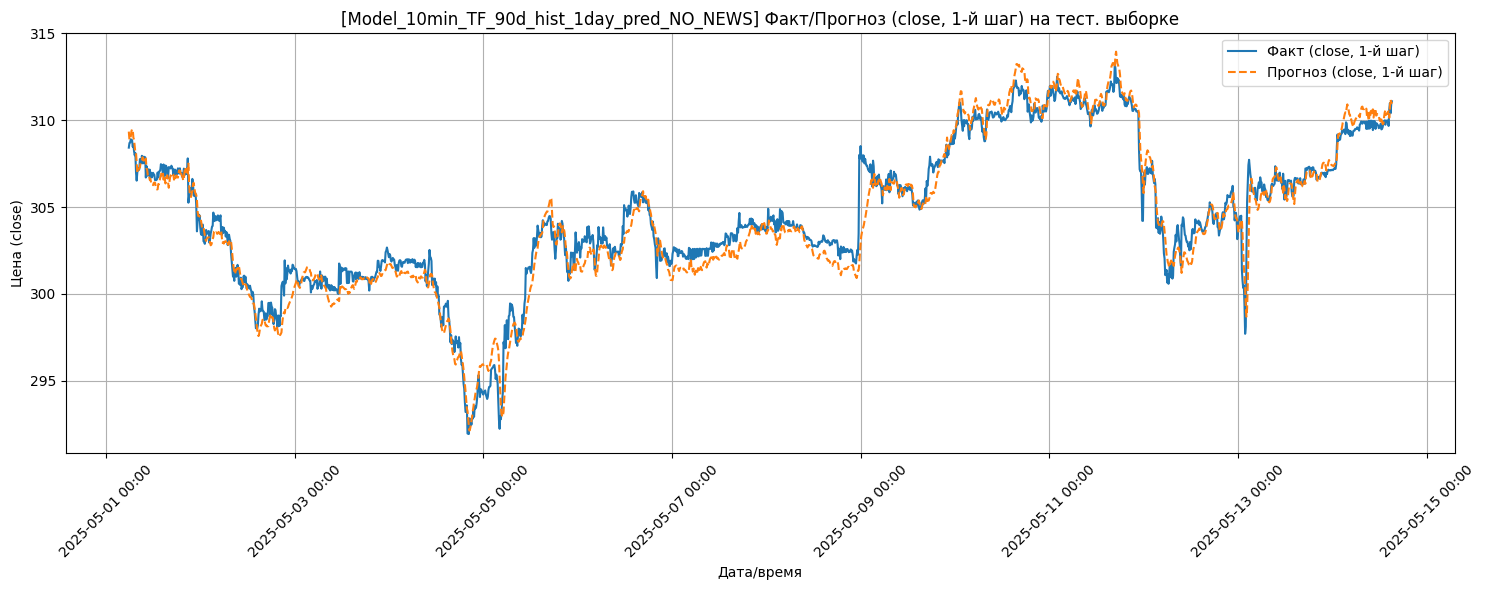


[Model_10min_TF_90d_hist_1day_pred_NO_NEWS][FINAL_TEST] Средняя MSE по всем 59 шагам прогноза (на тест. выборке): 4.5773


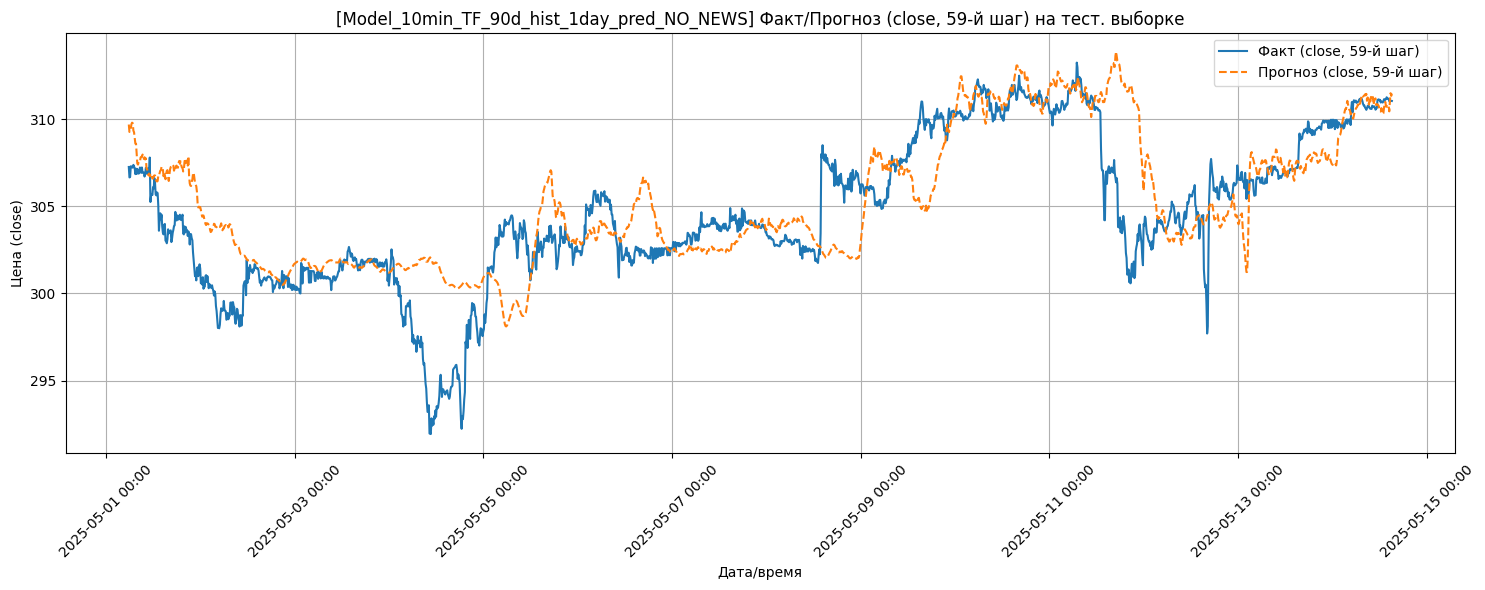


[Model_10min_TF_90d_hist_1day_pred_NO_NEWS][FUTURE_PREDICT] Запуск рекурсивного прогноза на 118 шагов...
[Model_10min_TF_90d_hist_1day_pred_NO_NEWS][FUTURE_PREDICT] Ошибка: недостаточно данных (129) после пересчета TA для будущего прогноза. Прогноз остановлен.
[Model_10min_TF_90d_hist_1day_pred_NO_NEWS][FUTURE_PREDICT] Рекурсивный прогноз завершен. Предсказано 59 шагов из 118 запрошенных.

[Model_10min_TF_90d_hist_1day_pred_NO_NEWS][FUTURE_PREDICT_RESULT] Будущие прогнозные значения (59 из 118 запрошенных шагов):
                     predicted_value
datetime                            
2025-05-18 17:30:00       311.707031
2025-05-18 17:40:00       311.617676
2025-05-18 17:50:00       311.640717
2025-05-18 18:00:00       311.698914
2025-05-18 18:10:00       311.680878


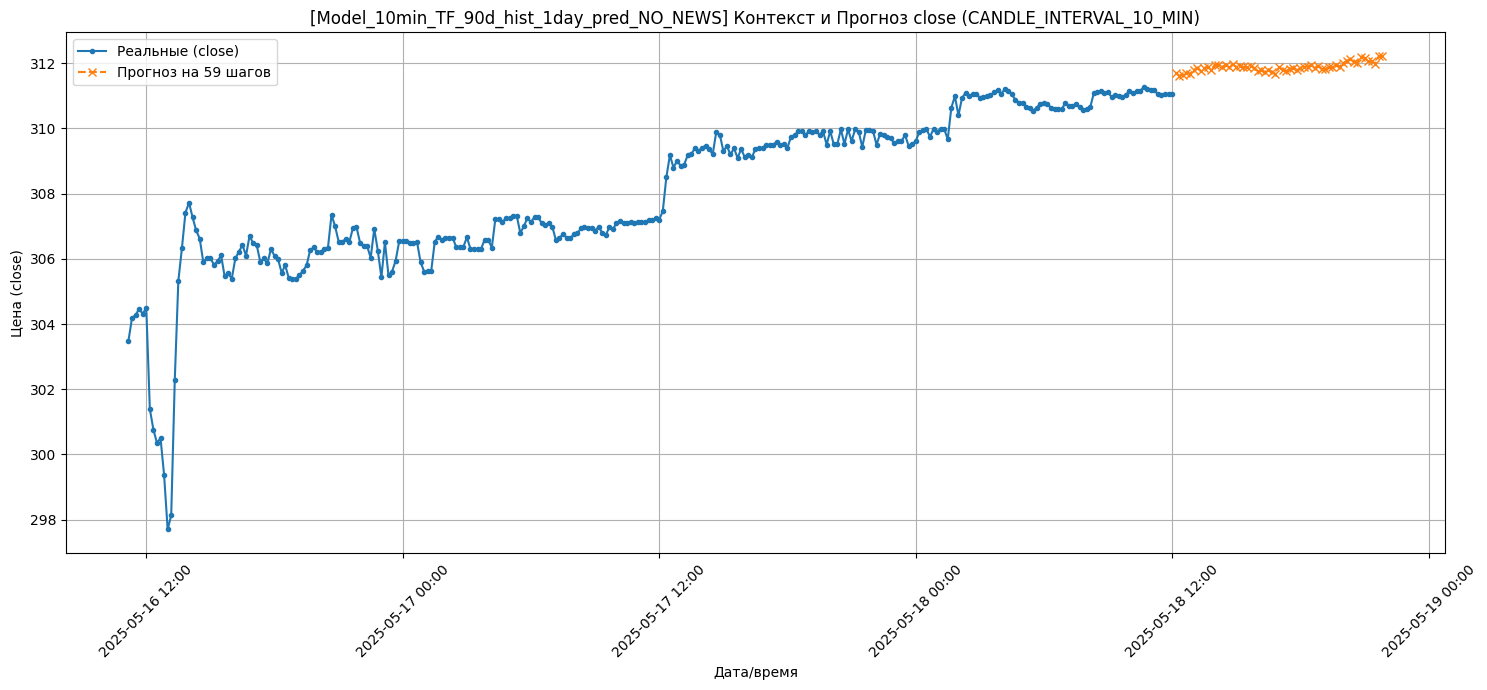


============================== ЗАВЕРШЕНИЕ ОБРАБОТКИ МОДЕЛИ: Model_10min_TF_90d_hist_1day_pred_NO_NEWS ==============================
[Model_1min_TF_30d_hist_5h_pred_WITH_NEWS][CV_FOLD] Результаты fold 2 (оценка на 1-м шаге прогноза):
  MSE: 0.1279
  RMSE: 0.3576
  MAE: 0.2469
  R2: 0.9966
  MSE_PCT: 0.0001 %
  RMSE_PCT: 0.1165 %
  MAE_PCT: 0.0804 %
  R2_PCT: 99.6584 %
[Model_1min_TF_30d_hist_5h_pred_WITH_NEWS][CV_FOLD] Результаты fold 1 (оценка на 1-м шаге прогноза):
  MSE: 0.1215
  RMSE: 0.3486
  MAE: 0.2530
  R2: 0.9967
  MSE_PCT: 0.0001 %
  RMSE_PCT: 0.1135 %
  MAE_PCT: 0.0824 %
  R2_PCT: 99.6686 %
[Model_5min_TF_60d_hist_1day_pred_WITH_NEWS][CV_FOLD] Результаты fold 2 (оценка на 1-м шаге прогноза):
  MSE: 0.7999
  RMSE: 0.8944
  MAE: 0.6246
  R2: 0.9927
  MSE_PCT: 0.0009 %
  RMSE_PCT: 0.2930 %
  MAE_PCT: 0.2046 %
  R2_PCT: 99.2712 %
[Model_1min_TF_30d_hist_5h_pred_WITH_NEWS][CV_FOLD] Результаты fold 3 (оценка на 1-м шаге прогноза):
  MSE: 0.0764
  RMSE: 0.2764
  MAE: 0.1855
  R2: 

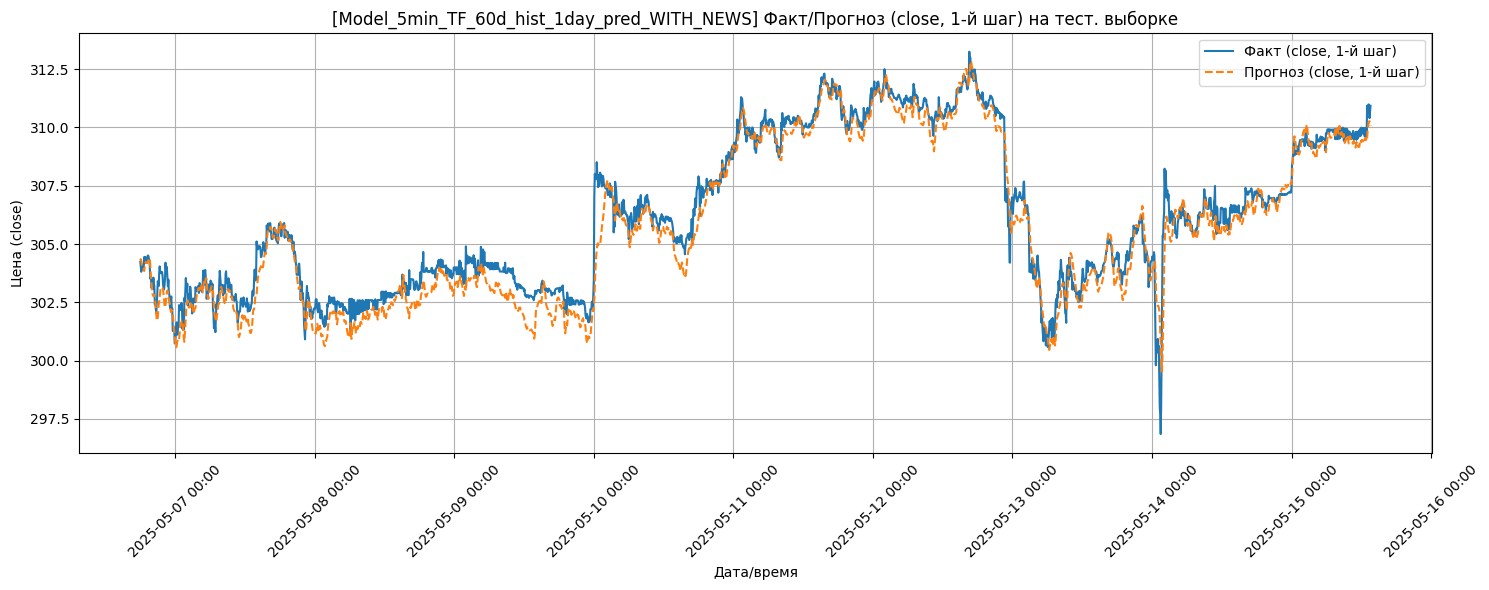


[Model_5min_TF_60d_hist_1day_pred_WITH_NEWS][FINAL_TEST] Средняя MSE по всем 117 шагам прогноза (на тест. выборке): 4.5315


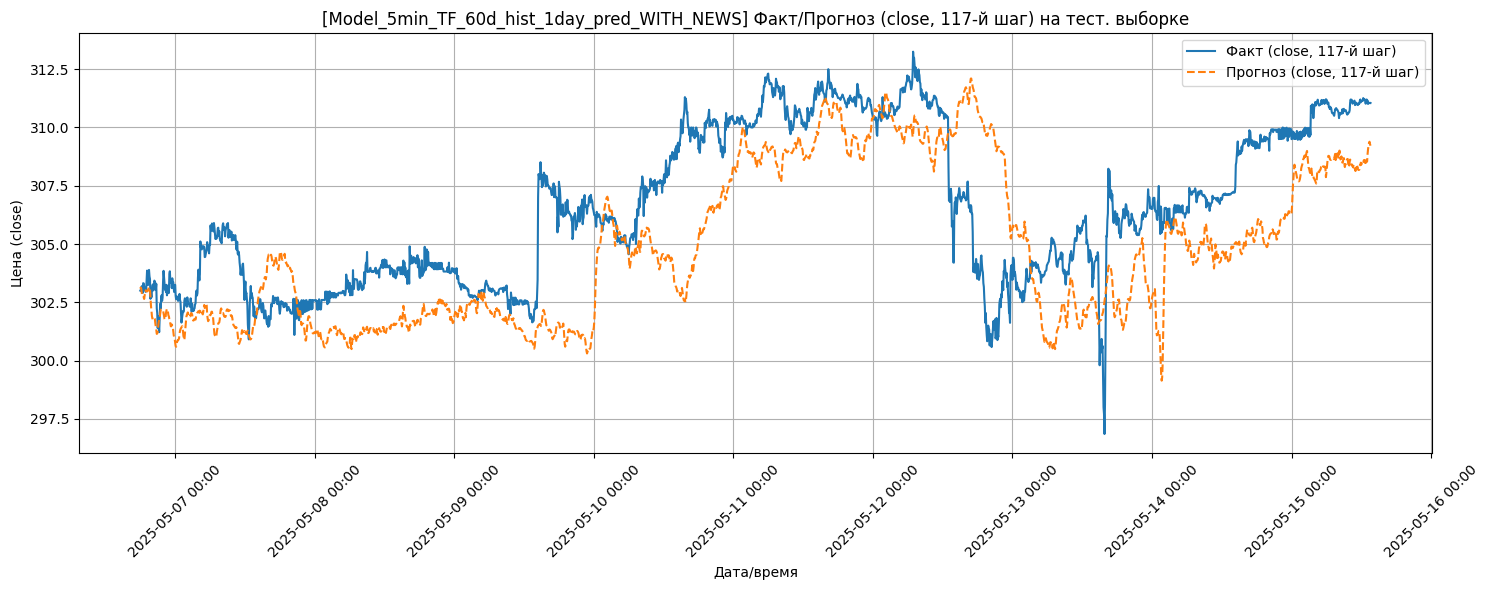


[Model_5min_TF_60d_hist_1day_pred_WITH_NEWS][FUTURE_PREDICT] Запуск рекурсивного прогноза на 234 шагов...
[Model_5min_TF_60d_hist_1day_pred_WITH_NEWS][FUTURE_PREDICT] Ошибка: недостаточно данных (187) после пересчета TA для будущего прогноза. Прогноз остановлен.
[Model_5min_TF_60d_hist_1day_pred_WITH_NEWS][FUTURE_PREDICT] Рекурсивный прогноз завершен. Предсказано 117 шагов из 234 запрошенных.

[Model_5min_TF_60d_hist_1day_pred_WITH_NEWS][FUTURE_PREDICT_RESULT] Будущие прогнозные значения (117 из 234 запрошенных шагов):
                     predicted_value
datetime                            
2025-05-18 17:25:00       310.477875
2025-05-18 17:30:00       310.522522
2025-05-18 17:35:00       310.633057
2025-05-18 17:40:00       310.603607
2025-05-18 17:45:00       310.578644


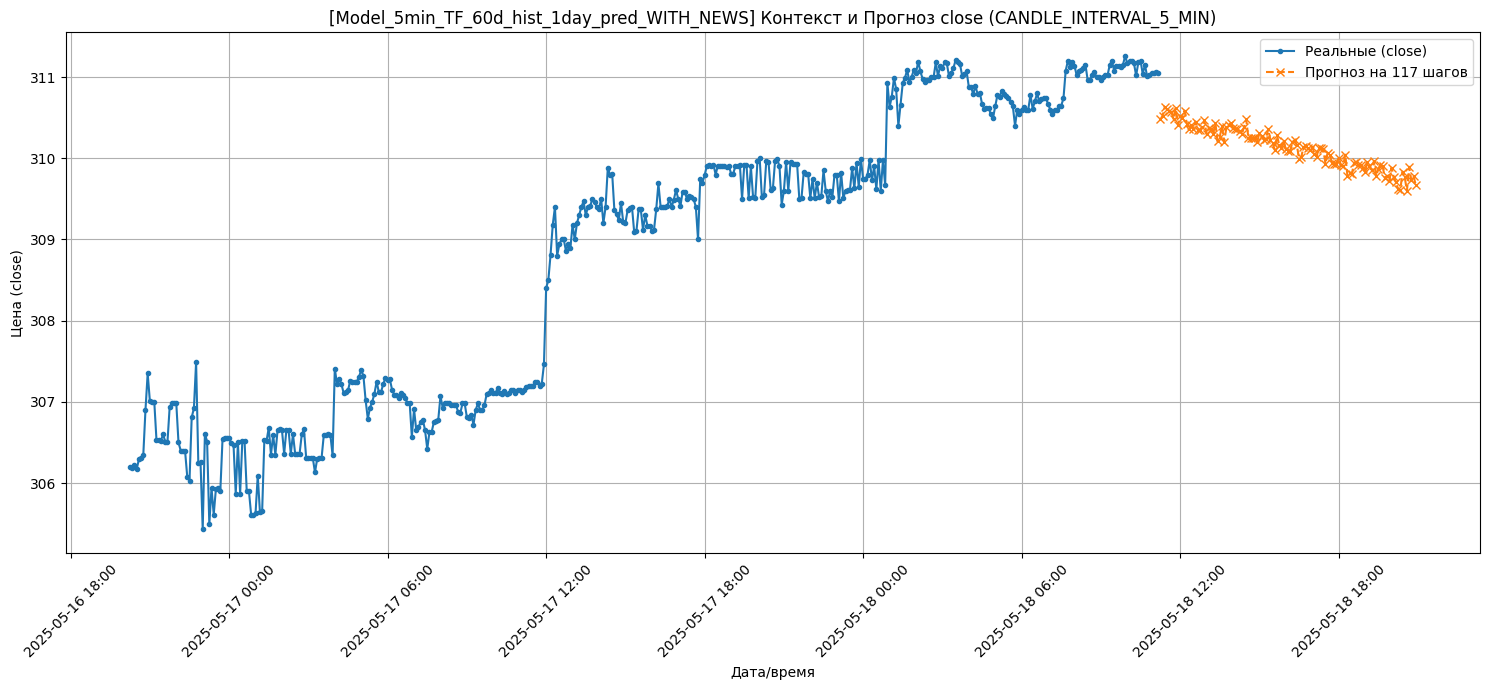


============================== ЗАВЕРШЕНИЕ ОБРАБОТКИ МОДЕЛИ: Model_5min_TF_60d_hist_1day_pred_WITH_NEWS ==============================
[Model_1min_TF_30d_hist_5h_pred_WITH_NEWS][CV_FOLD] Результаты fold 4 (оценка на 1-м шаге прогноза):
  MSE: 0.0659
  RMSE: 0.2566
  MAE: 0.1855
  R2: 0.9981
  MSE_PCT: 0.0001 %
  RMSE_PCT: 0.0836 %
  MAE_PCT: 0.0604 %
  R2_PCT: 99.8148 %

--- [Model_1min_TF_30d_hist_5h_pred_WITH_NEWS][CROSS_VALIDATION] Завершена ---
[Model_1min_TF_30d_hist_5h_pred_WITH_NEWS][CROSS_VALIDATION] Лучшая модель выбрана из фолда 4 (на основе MSE: 0.0659)
[Model_1min_TF_30d_hist_5h_pred_WITH_NEWS][CROSS_VALIDATION] Метрики лучшей модели (на её валидационном наборе, 1-й шаг прогноза):
  MSE: 0.0659
  RMSE: 0.2566
  MAE: 0.1855
  R2: 0.9981
  MSE_PCT: 0.0001 %
  RMSE_PCT: 0.0836 %
  MAE_PCT: 0.0604 %
  R2_PCT: 99.8148 %

--- [Model_1min_TF_30d_hist_5h_pred_WITH_NEWS][FINAL_TEST] Финальное тестирование модели ---
[Model_1min_TF_30d_hist_5h_pred_WITH_NEWS][FINAL_TEST] Метрики на т

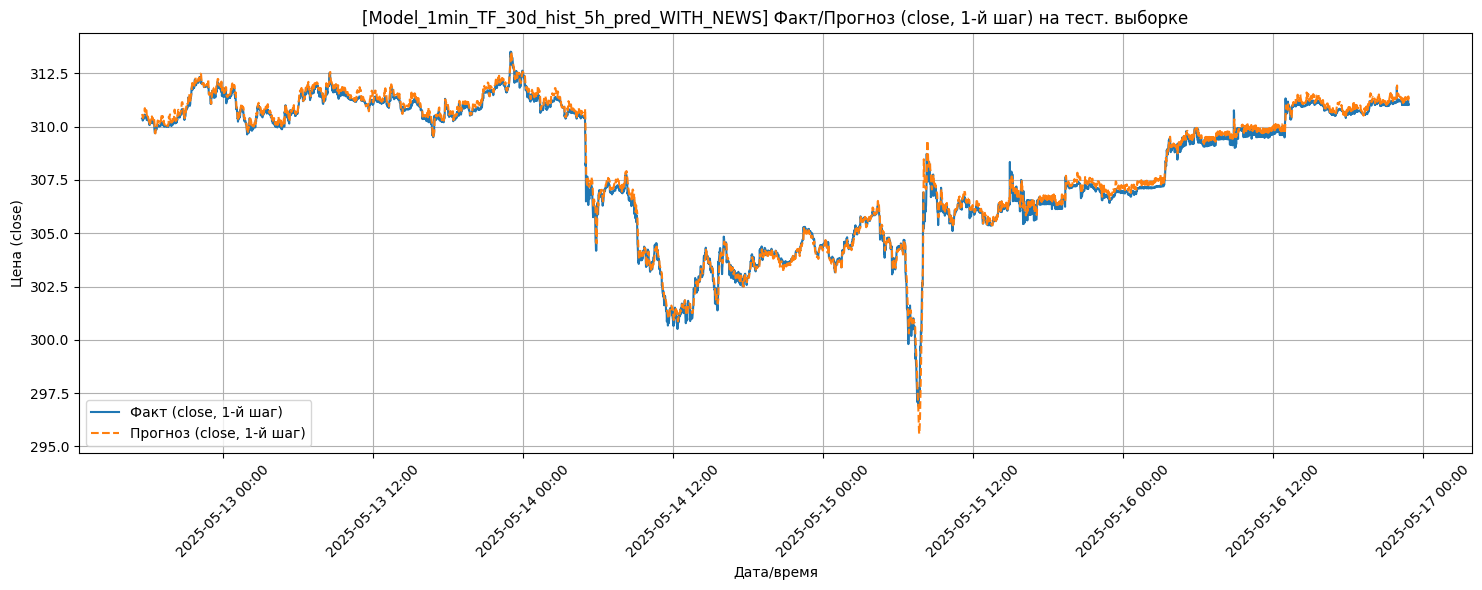


[Model_1min_TF_30d_hist_5h_pred_WITH_NEWS][FINAL_TEST] Средняя MSE по всем 15 шагам прогноза (на тест. выборке): 0.2505


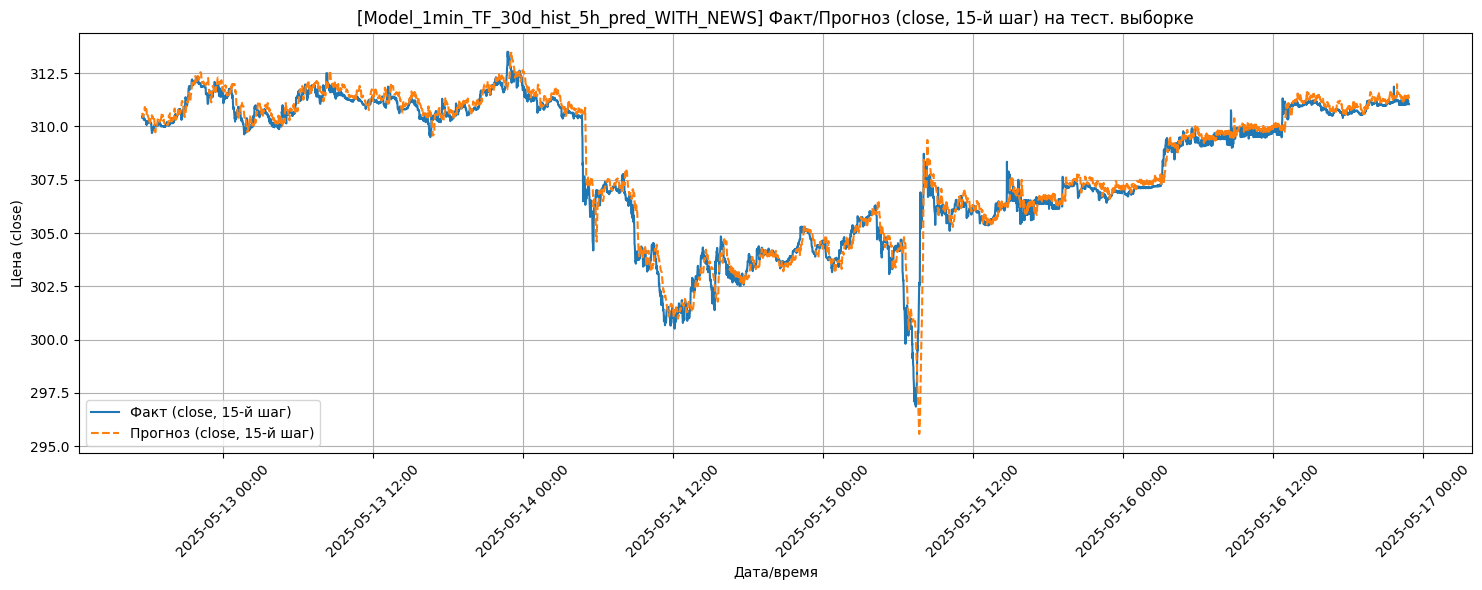


[Model_1min_TF_30d_hist_5h_pred_WITH_NEWS][FUTURE_PREDICT] Запуск рекурсивного прогноза на 300 шагов...
[Model_1min_TF_30d_hist_5h_pred_WITH_NEWS][FUTURE_PREDICT] Ошибка: недостаточно данных (85) после пересчета TA для будущего прогноза. Прогноз остановлен.
[Model_1min_TF_30d_hist_5h_pred_WITH_NEWS][FUTURE_PREDICT] Рекурсивный прогноз завершен. Предсказано 15 шагов из 300 запрошенных.

[Model_1min_TF_30d_hist_5h_pred_WITH_NEWS][FUTURE_PREDICT_RESULT] Будущие прогнозные значения (15 из 300 запрошенных шагов):
                     predicted_value
datetime                            
2025-05-18 17:22:00       311.227875
2025-05-18 17:23:00       311.221161
2025-05-18 17:24:00       311.174530
2025-05-18 17:25:00       311.216614
2025-05-18 17:26:00       311.192871


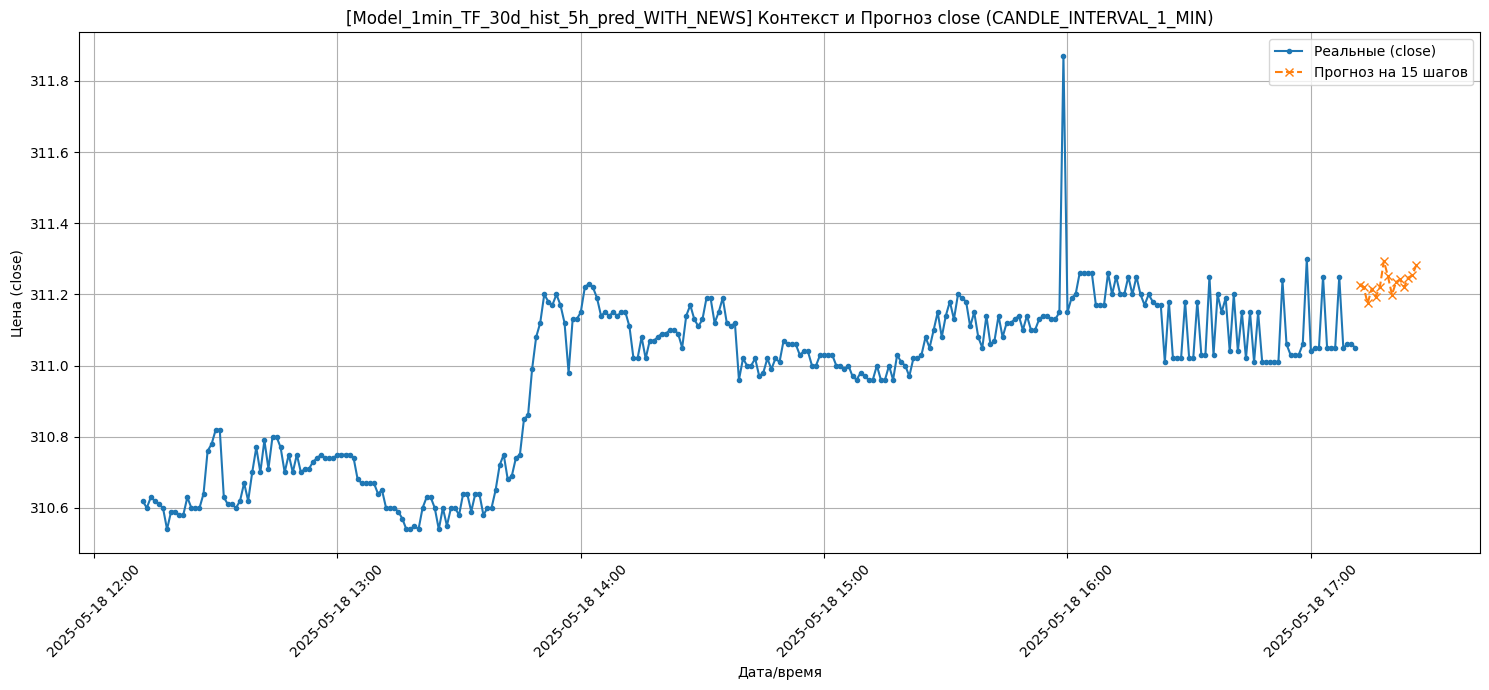


============================== ЗАВЕРШЕНИЕ ОБРАБОТКИ МОДЕЛИ: Model_1min_TF_30d_hist_5h_pred_WITH_NEWS ==============================

--- Работа всей программы прогнозирования завершена ---


In [63]:
# --- ОСНОВНОЙ БЛОК ВЫПОЛНЕНИЯ ---
if __name__ == "__main__":
    with print_lock:
        print("--- Начало работы основной программы прогнозирования ---")
        if TINKOFF_API_TOKEN == "YOUR_TINKOFF_API_KEY":
            print("ПРЕДУПРЕЖДЕНИЕ: TINKOFF_API_TOKEN не установлен! Загрузка данных Tinkoff не удастся.")
        if FINANCEMARKER_API_KEY == "YOUR_FINANCEMARKER_API_KEY_PLACEHOLDER":
            print("ПРЕДУПРЕЖДЕНИЕ: FINANCEMARKER_API_KEY не установлен! Будут использованы мок-данные для новостей.")

    # --- Загрузка модели анализа тональности ОДИН РАЗ перед запуском моделей ---
    # Это важно, т.к. загрузка тяжелая.
    # print_lock уже определен глобально.
    load_sentiment_model_if_needed(print_lock)

    # --- Конфигурации моделей для запуска ---
    # Пример: n_steps_out должен быть кратен количеству прогнозов в часах/днях, если хотим такой логики.
    # Например, для 5-минутного интервала, 1 час = 12 шагов. 1 день (торговый, ~8 часов) = 12 * 8 = 96 шагов.
    # n_steps_in обычно в 2-5 раз больше n_steps_out.

    model_configs_list = [
        {
            "name": "Model_1min_TF_30d_hist_5h_pred_WITH_NEWS",
            "days_history": 30,  # Сколько дней данных для обучения
            "candle_timeframe": CandleInterval.CANDLE_INTERVAL_1_MIN,
            "n_steps_in": 150,  # Сколько прошлых шагов (минут) смотрим для прогноза
            "n_steps_out": 15,  # На сколько шагов (минут) вперед прогнозируем за раз
            "future_predictions": 300,  # Общее количество будущих шагов (минут) для рекурсивного прогноза (5 часов)
            "use_news_features": True
        },
        {
            "name": "Model_5min_TF_60d_hist_1day_pred_WITH_NEWS",
            # 1 торговый день ~ 8-10 часов, для SBER ~9.75ч. 9.75*60/5 = 117
            "days_history": 60,
            "candle_timeframe": CandleInterval.CANDLE_INTERVAL_5_MIN,
            "n_steps_in": int(117 * 2.0),  # Смотрим на 2 дня назад (в 5-минутках)
            "n_steps_out": 117,  # Прогнозируем на 1 торговый день вперед (в 5-минутках)
            "future_predictions": 117 * 2,  # Прогнозируем на 2 торговых дня вперед
            "use_news_features": True
        },
        {
            "name": "Model_10min_TF_90d_hist_1day_pred_NO_NEWS",
            # 1 торговый день ~ 9.75*60/10 = 58.5 -> 58 или 59 шагов
            "days_history": 90,
            "candle_timeframe": CandleInterval.CANDLE_INTERVAL_10_MIN,
            "n_steps_in": int(59 * 2.5),
            "n_steps_out": 59,
            "future_predictions": 59 * 2,
            "use_news_features": False  # Эта модель без новостей
        },
        # Можно добавить другие конфигурации
    ]

    # --- Управление параллельным запуском моделей ---
    MIN_DESIRED_MODEL_WORKERS = 3  # Сколько моделей максимум хотим обрабатывать параллельно
    cpu_cores_count = os.cpu_count()
    if cpu_cores_count is None:
        with print_lock:
            print(
                f"Предупреждение: Не удалось определить количество CPU ядер. Будет использовано до {MIN_DESIRED_MODEL_WORKERS} потоков для моделей.")
        max_cpu_based_model_workers = MIN_DESIRED_MODEL_WORKERS
    else:
        max_cpu_based_model_workers = cpu_cores_count
        with print_lock:
            print(f"Обнаружено {cpu_cores_count} CPU ядер.")

    # Эффективное количество воркеров: не больше, чем моделей, и не больше, чем желаемое/доступное
    effective_model_workers = min(len(model_configs_list), max_cpu_based_model_workers)
    # Если MIN_DESIRED_MODEL_WORKERS > 0, то это жесткое ограничение сверху
    MAX_MODEL_WORKERS_TO_RUN = min(effective_model_workers,
                                   MIN_DESIRED_MODEL_WORKERS) if MIN_DESIRED_MODEL_WORKERS > 0 else effective_model_workers
    MAX_MODEL_WORKERS_TO_RUN = max(1, MAX_MODEL_WORKERS_TO_RUN) if len(model_configs_list) > 0 else 0

    with print_lock:
        print(f"INFO: Запуск обучения для {len(model_configs_list)} моделей.")
        if MIN_DESIRED_MODEL_WORKERS > 0: print(
            f"INFO: Запрошено до {MIN_DESIRED_MODEL_WORKERS} параллельных потоков для моделей.")
        print(
            f"INFO: Максимальное количество одновременно обучаемых моделей (MAX_MODEL_WORKERS_TO_RUN): {MAX_MODEL_WORKERS_TO_RUN}")
        if MAX_MODEL_WORKERS_TO_RUN > 1 and gpus:  # Если есть GPU и параллелизм
            print(
                "INFO: ВНИМАНИЕ! Если используется GPU, убедитесь, что TensorFlow настроен для роста памяти GPU (memory growth).")
            print(
                "INFO: В противном случае, TensorFlow может занять всю память GPU на первой же модели, и остальные модели не смогут запуститься на GPU.")
            print(
                "INFO: Рекомендуется установить MAX_MODEL_WORKERS_TO_RUN = 1 при использовании одной GPU без настройки memory growth.")

    if len(model_configs_list) > 0 and MAX_MODEL_WORKERS_TO_RUN > 0:
        with ThreadPoolExecutor(max_workers=MAX_MODEL_WORKERS_TO_RUN, thread_name_prefix="ModelPipeline") as executor:
            futures_models = [executor.submit(run_model_pipeline, config) for config in model_configs_list]
            for i, future_model_run in enumerate(as_completed(futures_models)):
                model_name_for_error = model_configs_list[i]['name'] if i < len(
                    model_configs_list) else 'unknown_model'  # Примерное имя для лога
                try:
                    future_model_run.result()  # Получаем результат (или исключение, если было)
                except Exception as e_model_pipeline:
                    with print_lock:
                        print(
                            f"КРИТИЧЕСКАЯ ОШИБКА (в потоке для модели '{model_name_for_error}'): Обработка модели завершилась с исключением на верхнем уровне: {e_model_pipeline}")
                        import traceback

                        print(traceback.format_exc())  # Печать полного стека ошибки
    elif len(model_configs_list) == 0:
        with print_lock:
            print("INFO: Нет конфигураций моделей для обучения. Завершение.")
    else:  # MAX_MODEL_WORKERS_TO_RUN == 0
        with print_lock:
            print(
                f"INFO: MAX_MODEL_WORKERS_TO_RUN ({MAX_MODEL_WORKERS_TO_RUN}) или количество моделей ({len(model_configs_list)}) равно 0. Обучение не будет запущено.")

    with print_lock:
        print("\n--- Работа всей программы прогнозирования завершена ---")